In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

if os.path.exists('/content/drive/MyDrive/HousingPulse/data/realestatedataset-miami-dade-county-fl-2026-10.csv'):
    ruta = '/content/drive/MyDrive/HousingPulse/data/realestatedataset-miami-dade-county-fl-2026-10.csv'
else:
    ruta = '../data/raw/realestatedataset-miami-dade-county-fl-2026-10.csv'

df = pd.read_csv(ruta)

print("Dataset cargado correctamente")
print(f"Filas: {df.shape[0]:,}")
print(f"Columnas: {df.shape[1]}")

/var/folders/g7/7b314lw172lcd6jfqp59gdk40000gn/T/ipykernel_36253/667517350.py:12: DtypeWarning: Columns (0: unit, 1: basement, 2: parcel_apn) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(ruta)


Dataset cargado correctamente
Filas: 1,015,955
Columnas: 30


## 1.0 Primera exploración

In [2]:
df.head()

,id,street,unit,city,state,zip,lat,lng,property_type,beds,...,hoa_fee,pool,garage,waterfront,fireplace,basement,listing_type,parcel_apn,county_fips,source_count
0,stp_gjPBaRMN1m,4371 NW 168th Ter,NaN,Miami Gardens,FL,33055.0,25.927070,-80.27210,single_family,3.0,...,NaN,NaN,True,NaN,NaN,NaN,NaN,3421080030860.0,12086,1
1,stp_E1qWgZD3jo,4310 NW 168th Ter,NaN,Miami Gardens,FL,33055.0,25.926695,-80.27094,single_family,3.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3421080030880.0,12086,1
2,stp_dkWx2qJv12,4320 NW 168th Ter,NaN,Miami Gardens,FL,33055.0,25.926867,-80.27117,single_family,3.0,...,NaN,NaN,True,NaN,NaN,NaN,NaN,3421080030890.0,12086,1
3,stp_b13bEL93kl,4330 NW 168th Ter,NaN,Miami Gardens,FL,33055.0,25.926655,-80.27139,single_family,3.0,...,NaN,NaN,True,NaN,NaN,NaN,NaN,3421080030900.0,12086,1
4,stp_KkyqNo3Vk0,4350 NW 168th Ter,NaN,Miami Gardens,FL,33055.0,25.926638,-80.27186,single_family,3.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3421080030920.0,12086,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1015955 entries, 0 to 1015954
Data columns (total 30 columns):
 #   Column           Non-Null Count    Dtype  
---  ------           --------------    -----  
 0   id               1015955 non-null  str    
 1   street           1015946 non-null  str    
 2   unit             108703 non-null   str    
 3   city             1015952 non-null  str    
 4   state            1015953 non-null  str    
 5   zip              1015938 non-null  float64
 6   lat              1015955 non-null  float64
 7   lng              1015955 non-null  float64
 8   property_type    1015955 non-null  str    
 9   beds             981454 non-null   float64
 10  baths            986433 non-null   float64
 11  sqft             955416 non-null   float64
 12  lot_sqft         503276 non-null   float64
 13  year_built       911455 non-null   float64
 14  status           1015955 non-null  str    
 15  list_price       1015892 non-null  float64
 16  last_sold_price  660888 non-n

In [4]:
df.shape

(1015955, 30)

In [5]:
df.columns.tolist()

['id',
 'street',
 'unit',
 'city',
 'state',
 'zip',
 'lat',
 'lng',
 'property_type',
 'beds',
 'baths',
 'sqft',
 'lot_sqft',
 'year_built',
 'status',
 'list_price',
 'last_sold_price',
 'last_sold_date',
 'heating_type',
 'central_air',
 'hoa_fee',
 'pool',
 'garage',
 'waterfront',
 'fireplace',
 'basement',
 'listing_type',
 'parcel_apn',
 'county_fips',
 'source_count']

## 1.1 Análisis inicial del dataset

Vamos a comprobar los tipos de variables.

In [6]:
df.dtypes

id                     str
street                 str
unit                   str
city                   str
state                  str
zip                float64
lat                float64
lng                float64
property_type          str
beds               float64
baths              float64
sqft               float64
lot_sqft           float64
year_built         float64
status                 str
list_price         float64
last_sold_price    float64
last_sold_date         str
heating_type           str
central_air         object
hoa_fee            float64
pool                object
garage              object
waterfront          object
fireplace           object
basement            object
listing_type           str
parcel_apn          object
county_fips          int64
source_count         int64
dtype: object

Ahora analizamos los valores nulos que tenemos

In [7]:
nulos = pd.DataFrame({
    'Valores nulos': df.isnull().sum(),
    'Porcentaje nulos': df.isnull().mean() * 100
})

nulos.sort_values('Porcentaje nulos', ascending=False)

,Valores nulos,Porcentaje nulos
basement,1013115,99.720460
listing_type,1012670,99.676659
fireplace,1001306,98.558105
waterfront,944643,92.980791
unit,907252,89.300412
pool,905964,89.173635
garage,704114,69.305629
central_air,681099,67.040272
hoa_fee,678048,66.739964
heating_type,653349,64.308852


Veamos si tenemos registros duplicados

In [8]:
print(f"Registros duplicados: {df.duplicated().sum():,}")

Registros duplicados: 0


Observamos que no tenemos ningun registro duplicado.

## 1.2 Selección del tipo de inmueble

Comprobamos los tipos de inmuebles disponibles

In [9]:
df['property_type'].value_counts()

property_type
single_family    422006
condo            331509
townhouse        113789
apartment         96110
multi_family      45811
land               3955
manufactured       1845
other               930
Name: count, dtype: int64

Cogemos solo los registros de viviendas del tipo 'single_family'. Es decir, filtramos exclusivamente por viviendas unifamiliares.


In [10]:
df_single = df[df['property_type'] == 'single_family'].copy()

print(f"Registros iniciales: {len(df):,}")
print(f"Viviendas unifamiliares: {len(df_single):,}")
print(f"Porcentaje del dataset: {len(df_single) / len(df) * 100:.2f}%")

Registros iniciales: 1,015,955
Viviendas unifamiliares: 422,006
Porcentaje del dataset: 41.54%


Volvemos a realizar un analisis de valores nulos con el dataset ya filtrado

In [11]:
nulos_single = pd.DataFrame({
    'Valores nulos': df_single.isnull().sum(),
    'Porcentaje nulos': df_single.isnull().mean() * 100
})

nulos_single.sort_values('Porcentaje nulos', ascending=False)

,Valores nulos,Porcentaje nulos
listing_type,420981,99.757112
basement,420089,99.545741
unit,411539,97.519704
fireplace,409585,97.056677
waterfront,404064,95.748402
pool,364696,86.419624
hoa_fee,349239,82.756880
central_air,280930,66.570144
heating_type,275622,65.312342
garage,233608,55.356559


Ahora analizamos las variables numéricas

In [12]:
df_single[['beds', 'baths', 'sqft', 'lot_sqft',
           'year_built', 'list_price', 'last_sold_price']].describe().round(2)

,beds,baths,sqft,lot_sqft,year_built,list_price,last_sold_price
count,412320.00,412771.00,410569.00,3.820030e+05,402063.00,4.219860e+05,3.341850e+05
mean,3.38,2.26,2012.84,1.026425e+05,1973.28,9.558249e+05,4.964836e+05
std,0.97,1.11,2144.04,5.207148e+06,23.54,2.191729e+06,1.493298e+06
min,0.00,0.00,0.00,0.000000e+00,1730.00,0.000000e+00,0.000000e+00
25%,3.00,2.00,1365.00,5.867000e+03,1954.00,4.833000e+05,1.379000e+05
50%,3.00,2.00,1740.00,7.588000e+03,1970.00,6.138000e+05,2.750000e+05
75%,4.00,3.00,2284.00,9.996000e+03,1993.00,8.229000e+05,4.800000e+05
max,25.00,30.00,722777.00,4.909212e+08,2028.00,2.370000e+08,1.700000e+08


## 1.3. Análisis de valores inconsistentes y extremos

Comprobamos cuántas viviendas tienen variables iguales o inferiores a cero en las variables principales


In [13]:
variables = [
    'beds',
    'baths',
    'sqft',
    'lot_sqft',
    'year_built',
    'list_price',
    'last_sold_price'
]

for variable in variables:
    print(f"\n{variable}")
    print(f"Valores iguales a 0: {(df_single[variable] == 0).sum():,}")
    print(f"Valores negativos: {(df_single[variable] < 0).sum():,}")


beds
Valores iguales a 0: 1,177
Valores negativos: 0

baths
Valores iguales a 0: 1,097
Valores negativos: 0

sqft
Valores iguales a 0: 755
Valores negativos: 0

lot_sqft
Valores iguales a 0: 1,455
Valores negativos: 0

year_built
Valores iguales a 0: 0
Valores negativos: 0

list_price
Valores iguales a 0: 2,101
Valores negativos: 0

last_sold_price
Valores iguales a 0: 6
Valores negativos: 0


### 1.3.1 Veamos ahora cúantas viviendas tiene un año de construcción posterior a 2026

In [14]:
print("Años de construcción posteriores a 2026:")

df_single[df_single['year_built'] > 2026][
    ['street', 'city', 'year_built', 'list_price']
].head(10)

Años de construcción posteriores a 2026:


,street,city,year_built,list_price
412544,190 Casuarina Concourse,Coral Gables,2027.0,75000000.0
598159,6520 San Vicente Street Coral,Miami,2027.0,7500000.0
632191,5991 SW 35th St,Miami,2027.0,2950000.0
709202,1011 Links Dr,Miami Beach,2027.0,32000000.0
709341,1140 SW 22 Ter,Miami,2027.0,2275000.0
709777,1142 SW 22 Ter,Miami,2027.0,2325000.0
752413,2664 SW 17th Ave,Miami,2027.0,8700000.0
775432,7150 NE 72nd St,Miami,2027.0,8250000.0
778516,7105 NE 10th Ave,Miami,2027.0,17500000.0
778517,7150 NE 72nd St,Miami,2027.0,8250000.0


In [15]:
(df_single['year_built'] > 2026).sum()

np.int64(42)

### 1.3.2 Analizamos la distribución de los precios

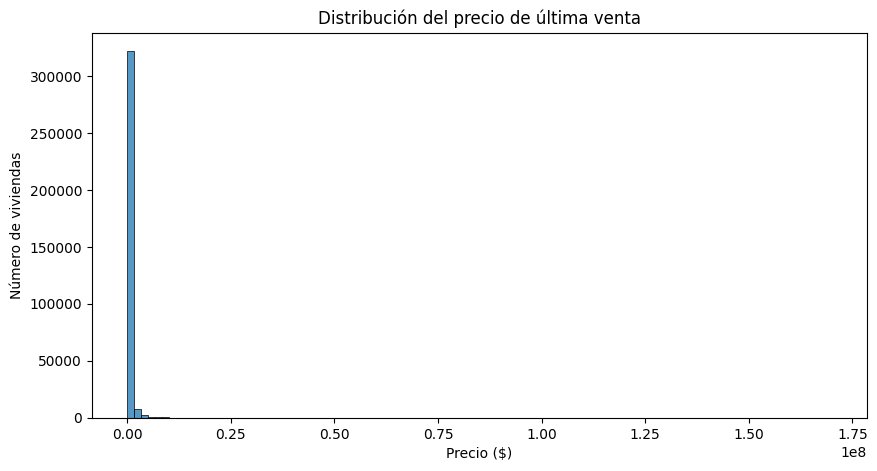

In [16]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df_single['last_sold_price'].dropna(),
    bins=100
)

plt.title('Distribución del precio de última venta')
plt.xlabel('Precio ($)')
plt.ylabel('Número de viviendas')

plt.show()

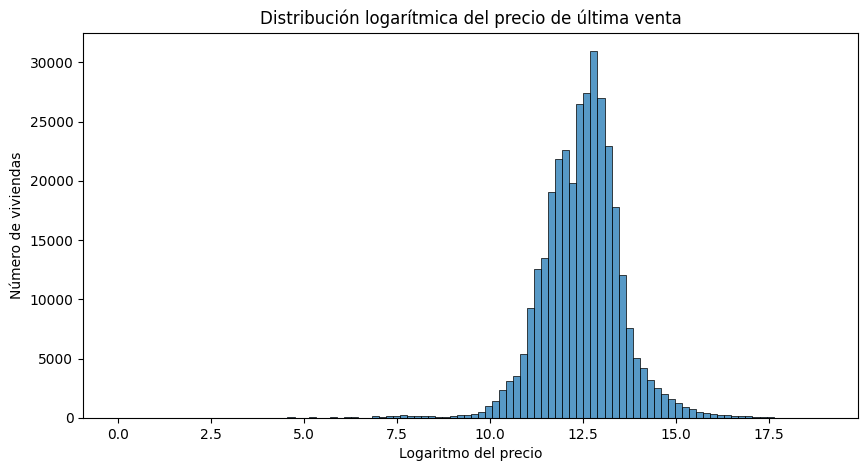

In [17]:
plt.figure(figsize=(10, 5))

sns.histplot(
    np.log1p(df_single['last_sold_price'].dropna()),
    bins=100
)

plt.title('Distribución logarítmica del precio de última venta')
plt.xlabel('Logaritmo del precio')
plt.ylabel('Número de viviendas')

plt.show()

### 1.3.3. Análisis de valores extremos en los precios

In [18]:
df_single['last_sold_price'].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
).round(2)

count    3.341850e+05
mean     4.964836e+05
std      1.493298e+06
min      0.000000e+00
1%       2.100000e+04
5%       5.400000e+04
25%      1.379000e+05
50%      2.750000e+05
75%      4.800000e+05
90%      8.014540e+05
95%      1.320000e+06
99%      4.250000e+06
max      1.700000e+08
Name: last_sold_price, dtype: float64

Identificamos las viviendas con los precios mas elevados

In [19]:
df_single.nlargest(20, 'last_sold_price')[
    ['street', 'city', 'beds', 'baths', 'sqft',
     'year_built', 'last_sold_price', 'last_sold_date']
]

,street,city,beds,baths,sqft,year_built,last_sold_price,last_sold_date
983991,7 Indian Creek Island Rd,Indian Creek,9.0,13.0,27889.0,2026.0,170000000.0,2026-03-02
977143,18 La Gorce Cir,Miami Beach,12.0,20.5,NaN,1936.0,122125121.0,2024-10-25
1008388,10380 NW 68th Ter,Doral,5.0,5.0,3000.0,2020.0,107800000.0,2024-09-12
752642,3031 Brickell Ave,Miami,12.0,17.0,19919.0,1913.0,106875000.0,2022-09-02
1014775,6470 SW 33rd St,Miami,4.0,3.0,NaN,2018.0,102700000.0,2025-09-11
907944,3585 Anchorage Way,Miami,13.0,16.5,11855.0,2008.0,101500000.0,2025-12-29
362343,702 SW 1st St,Miami,NaN,NaN,3966.0,2021.0,92000000.0,2022-07-01
457772,3142 W 77th Pl,Hialeah,4.0,2.0,1500.0,1994.0,90990000.0,1994-01-13
866286,7403 Sw 124 Court,Miami,5.0,4.0,4255.0,NaN,89100000.0,2016-04-27
398244,28 Indian Creek Island Rd,Indian Creek,6.0,9.0,12135.0,2002.0,87000000.0,2024-06-03


### 1.3.4. Análisis temporal de las últimas ventas

Convertimos la variable fecha de venta a formato date time

In [20]:
df_single['last_sold_date'] = pd.to_datetime(
    df_single['last_sold_date'],
    errors='coerce'
)

Comprobamos el periodo temporal

In [21]:
print("Primera fecha de venta:",
      df_single['last_sold_date'].min())

print("Última fecha de venta:",
      df_single['last_sold_date'].max())

print("Fechas nulas:",
      df_single['last_sold_date'].isnull().sum())

Primera fecha de venta: 1900-01-01 00:00:00
Última fecha de venta: 2026-06-18 00:00:00
Fechas nulas: 87074


Miramos la distribucion de la venta por año

In [22]:
ventas_por_anio = (
    df_single['last_sold_date']
    .dt.year
    .value_counts()
    .sort_index()
)

ventas_por_anio

last_sold_date
1900.0     1026
1927.0        1
1970.0       11
1971.0      306
1972.0      332
1973.0      656
1974.0      443
1975.0      526
1976.0      749
1977.0      926
1978.0     1029
1979.0      761
1980.0      736
1981.0      625
1982.0      473
1983.0      778
1984.0      870
1985.0      963
1986.0     1181
1987.0     1538
1988.0     1455
1989.0     1479
1990.0     1748
1991.0     1567
1992.0     1748
1993.0     4964
1994.0     6208
1995.0     5497
1996.0     6064
1997.0     5795
1998.0     6796
1999.0     7323
2000.0     7475
2001.0     7787
2002.0     6887
2003.0     7555
2004.0     8182
2005.0     7099
2006.0     5597
2007.0     4110
2008.0     3959
2009.0     6366
2010.0     6922
2011.0     8014
2012.0     9192
2013.0    11687
2014.0    11874
2015.0    12178
2016.0    12604
2017.0    12984
2018.0    13796
2019.0    14115
2020.0    15629
2021.0    18378
2022.0    14383
2023.0    12266
2024.0    12663
2025.0    12640
2026.0     6016
Name: count, dtype: int64

Representamos las ventas por año

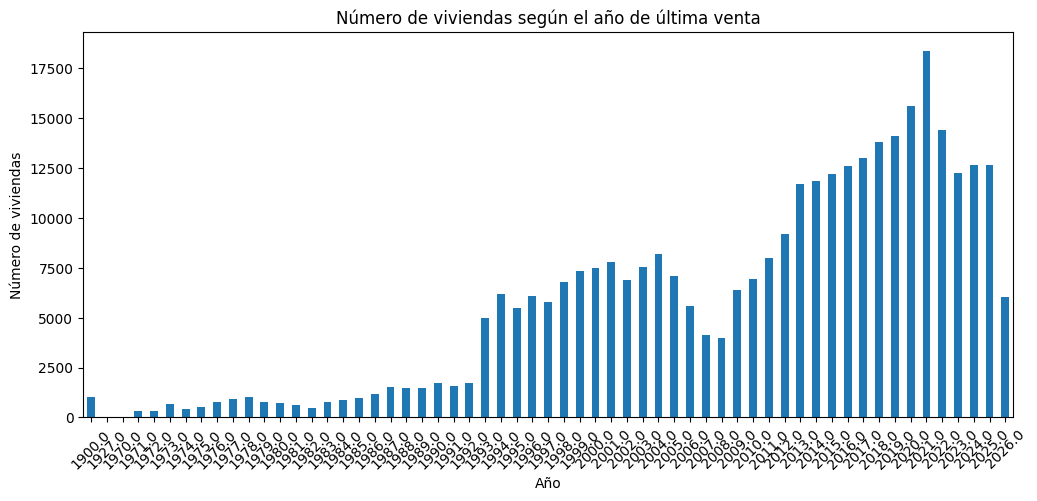

In [23]:
plt.figure(figsize=(12, 5))

ventas_por_anio.plot(kind='bar')

plt.title('Número de viviendas según el año de última venta')
plt.xlabel('Año')
plt.ylabel('Número de viviendas')
plt.xticks(rotation=45)

plt.show()

### 1.3.5. Tratamiento de fechas inconsistentes

In [24]:
# Creamos una copia de la fecha original
df_single['last_sold_date_clean'] = df_single['last_sold_date'].copy()

# Identificamos las fechas de 1900
fechas_1900 = (
    df_single['last_sold_date_clean'].dt.year == 1900
)

print("Fechas de 1900:", fechas_1900.sum())

Fechas de 1900: 1026


Marcaremos las fechas de 1900 como nulas porque detectamos que son valores de relleno o fechas incorrectas, no fechas reales de compraventa.

In [25]:
# Sustituimos las fechas de 1900 por valores nulos
df_single.loc[
    fechas_1900,
    'last_sold_date_clean'
] = pd.NaT

In [26]:
print("Fechas nulas originales:",
      df_single['last_sold_date'].isnull().sum())

print("Fechas nulas tras la corrección:",
      df_single['last_sold_date_clean'].isnull().sum())

Fechas nulas originales: 87074
Fechas nulas tras la corrección: 88100


### 1.3.6 Tratamiento del periodo de las ventas

Vamos a acotar el rango de fechas de la venta de nuestros inmuebles desde 2020- 2027, por las siguientes razones:



1.   **Representatividad del mercado inmobiliario actual**: El objetivo de HousingPulse es desarrollar un modelo que permita estimar el precio de una vivienda utilizando información del mercado inmobiliario reciente.
Por tanto, una compraventa de 2010 no necesariamente refleja las condiciones de mercado de 2026.
2.   **Evitar utilizar operaciones demasiado antiguas**: Si incorporamos ventas de hace 10, 15 o 20 años, el modelo podría aprender relaciones entre las características de las viviendas y unos precios que corresponden a condiciones económicas muy diferentes.
Por ejemplo, una vivienda vendida por 250.000 $ en 2012 podría tener un valor de mercado muy diferente en 2026, aunque sus características físicas sean similares.

1.   **Mejorar la utilidad de las predicciones**: Queremos que HousingPulse sea una herramienta orientada a estimar valores inmobiliarios actuales, no a reproducir los precios históricos de cualquier época. Trabajar con operaciones desde 2020 permite centrar el análisis en un periodo más próximo al mercado que queremos representar.





In [27]:
# Registros con fecha de venta desde 2020
desde_2020 = df_single[
    df_single['last_sold_date_clean'] >= '2020-01-01'
].copy()

print(f"Registros desde 2020: {len(desde_2020):,}")

print(
    "Registros con precio de venta:",
    desde_2020['last_sold_price'].notna().sum()
)

print(
    "Porcentaje con precio de venta:",
    round(desde_2020['last_sold_price'].notna().mean() * 100, 2),
    "%"
)

Registros desde 2020: 91,975
Registros con precio de venta: 91974
Porcentaje con precio de venta: 100.0 %


In [28]:
# Distribución de ventas desde 2020
ventas_recientes = (
    desde_2020['last_sold_date_clean']
    .dt.year
    .value_counts()
    .sort_index()
)

ventas_recientes

last_sold_date_clean
2020    15629
2021    18378
2022    14383
2023    12266
2024    12663
2025    12640
2026     6016
Name: count, dtype: int64

### **Justificación del periodo de análisis (2020-2026)**

Para el desarrollo de HousingPulse se ha decidido trabajar exclusivamente con viviendas cuya última fecha de compraventa sea igual o posterior al 1 de enero de 2020.

Esta decisión responde principalmente a la necesidad de construir un modelo de valoración inmobiliaria que represente las condiciones recientes del mercado de Miami-Dade County.

El mercado inmobiliario está sujeto a cambios a lo largo del tiempo, influenciados por factores económicos como la inflación, los tipos de interés, la oferta y la demanda y la evolución de los precios de la vivienda. Por este motivo, utilizar operaciones demasiado antiguas podría introducir información poco representativa de las condiciones actuales del mercado.

La incorporación de transacciones anteriores a 2020 podría provocar que el modelo aprendiese relaciones entre las características de los inmuebles y unos precios correspondientes a contextos económicos diferentes.

Por tanto, se establece 2020 como año de referencia inicial para:

- Priorizar operaciones inmobiliarias recientes.
- Reducir la influencia de condiciones de mercado históricas que pueden haber cambiado significativamente.
- Mejorar la representatividad de los datos respecto al mercado que se pretende analizar.
- Mantener un volumen de observaciones suficiente para desarrollar los posteriores modelos de Machine Learning.

Como resultado de este filtro temporal, se obtienen **91.975 registros** con fecha de última venta igual o posterior al 1 de enero de 2020, antes de aplicar las últimas operaciones de limpieza.

El periodo analizado comprende desde el 1 de enero de 2020 hasta el 18 de junio de 2026, fecha de la última operación disponible en el conjunto de datos.

### 1.3.7. Creación del conjunto de datos del periodo seleccionado

Creamos nuestro dataset con los registros de viviendas desde 2020 hacia delante

In [29]:
df_recent = desde_2020.copy()

print(f"Total de registros: {len(df_recent):,}")
print(f"Fecha inicial: {df_recent['last_sold_date_clean'].min()}")
print(f"Fecha final: {df_recent['last_sold_date_clean'].max()}")

Total de registros: 91,975
Fecha inicial: 2020-01-01 00:00:00
Fecha final: 2026-06-18 00:00:00


Investigamos el registro que no tiene precio

In [30]:
df_recent[df_recent['last_sold_price'].isna()][
    ['street', 'city', 'beds', 'baths', 'sqft',
     'last_sold_date_clean', 'last_sold_price']
]

,street,city,beds,baths,sqft,last_sold_date_clean,last_sold_price
904934,11400 NW 34th St,Doral,NaN,NaN,NaN,2020-02-13,NaN


Comprobamos si existen precios iguales a cero o negativos dentro de nuestro periodo

In [31]:
print(
    "Precios iguales a cero:",
    (df_recent['last_sold_price'] == 0).sum()
)

print(
    "Precios negativos:",
    (df_recent['last_sold_price'] < 0).sum()
)

Precios iguales a cero: 1
Precios negativos: 0


### 1.3.8. Revisión de registros sin precio válido

Queremos identificar el registro cuyo precio es 0 y además comprobaremos si coincide con el registro que no tiene precio

In [32]:
# Registros sin precio de venta
sin_precio = df_recent[
    df_recent['last_sold_price'].isna()
]

# Registros con precio igual a cero
precio_cero = df_recent[
    df_recent['last_sold_price'] == 0
]

print("Registros sin precio:", len(sin_precio))
print("Registros con precio cero:", len(precio_cero))

print("\nRegistros sin precio:")
display(sin_precio)

print("\nRegistros con precio cero:")
display(precio_cero)

Registros sin precio: 1
Registros con precio cero: 1

Registros sin precio:


,id,street,unit,city,state,zip,lat,lng,property_type,beds,...,pool,garage,waterfront,fireplace,basement,listing_type,parcel_apn,county_fips,source_count,last_sold_date_clean
904934,stp_X1Nml7pYkn,11400 NW 34th St,NaN,Doral,FL,33178.0,25.804655,-80.38156,single_family,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12086,1,2020-02-13



Registros con precio cero:


,id,street,unit,city,state,zip,lat,lng,property_type,beds,...,pool,garage,waterfront,fireplace,basement,listing_type,parcel_apn,county_fips,source_count,last_sold_date_clean
912805,stp_r1bpEnGJjK,7135 NW 36th Ave,NaN,Miami,FL,33147.0,25.839075,-80.25487,single_family,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12086,1,2020-10-26


Son registros diferentes

Ahora vamos a analizar los valores nulos en el periodo elegido

In [33]:
nulos_recent = pd.DataFrame({
    'Valores nulos': df_recent.isnull().sum(),
    'Porcentaje nulos': df_recent.isnull().mean() * 100
})

nulos_recent.sort_values(
    'Porcentaje nulos',
    ascending=False
).round(2)

,Valores nulos,Porcentaje nulos
basement,91678,99.68
listing_type,91615,99.61
fireplace,86750,94.32
unit,83805,91.12
waterfront,80160,87.15
hoa_fee,71932,78.21
pool,42291,45.98
garage,40294,43.81
central_air,24490,26.63
heating_type,18886,20.53


Comprobamos duplicados en el periodo seleccionado

In [34]:
print(
    "Duplicados exactos:",
    df_recent.duplicated().sum()
)

print(
    "Registros con parcel_apn duplicado:",
    df_recent['parcel_apn'].duplicated().sum()
)

print(
    "Parcel APN nulos:",
    df_recent['parcel_apn'].isnull().sum()
)

print(
    "APN duplicados (sin contar nulos):",
    df_recent['parcel_apn'].dropna().duplicated().sum()
)

Duplicados exactos: 0
Registros con parcel_apn duplicado: 1780
Parcel APN nulos: 1408
APN duplicados (sin contar nulos): 373


Investigamos los APN repetidos

In [35]:
apn_repetidos = (
    df_recent['parcel_apn']
    .value_counts()
    .loc[lambda x: x > 1]
)

print("Número de APN distintos repetidos:", len(apn_repetidos))

apn_repetidos.head(10)

Número de APN distintos repetidos: 365


parcel_apn
1078110190010    4
3040050360700    3
3078010090290    3
3050320780060    3
3069350311730    3
3021060160110    3
3059080130500    3
3059110130180    2
3059110130560    2
3059110130650    2
Name: count, dtype: int64

Tenemos 365 identificadores parcel_apn diferentes que aparecen más de una vez.

Hay una pequeña diferencia entre los 373 y los 365:
- 365: número de identificadores distintos que están repetidos.
- 373: número de apariciones adicionales de esos identificadores, contando desde la segunda aparición.
Por ejemplo, el primer APN aparece 4 veces. Eso supone 3 apariciones adicionales.

Comprobamos qué ocurre con esas propiedades, para ello inspeccionamos los registros asociados a los 10 primeros APN repetidos

In [36]:
apn_ejemplo = apn_repetidos.head(10).index

df_apn_repetidos = df_recent[
    df_recent['parcel_apn'].isin(apn_ejemplo)
].sort_values(
    ['parcel_apn', 'last_sold_date_clean']
)

df_apn_repetidos

,id,street,unit,city,state,zip,lat,lng,property_type,beds,...,pool,garage,waterfront,fireplace,basement,listing_type,parcel_apn,county_fips,source_count,last_sold_date_clean
565307,stp_DkX9VnMe1A,1880 NW 14th Ter,NaN,Homestead,FL,33030.0,25.457104,-80.448880,single_family,4.0,...,True,True,NaN,NaN,NaN,NaN,1078110190010,12086,1,2021-10-20
658100,stp_GkVRKb2JkE,1880 NW 14th Ave,NaN,Homestead,FL,33030.0,25.457104,-80.448880,single_family,4.0,...,True,True,NaN,NaN,NaN,NaN,1078110190010,12086,1,2021-10-20
834455,stp_ozLgqXlR1e,1420 NW 19th St,,Homestead,FL,33030.0,25.487323,-80.494964,single_family,4.0,...,NaN,NaN,NaN,NaN,NaN,NaN,1078110190010,12086,2,2021-11-17
712666,stp_dkWKpg0xk2,1875 NW 14th Ter,NaN,Homestead,FL,33030.0,25.485796,-80.494240,single_family,4.0,...,True,True,NaN,NaN,NaN,NaN,1078110190010,12086,1,2021-11-19
640394,stp_PjxAqr6mkO,19217 NW 53rd Ave,NaN,Opa Locka,FL,33055.0,25.946966,-80.289360,single_family,3.0,...,True,NaN,NaN,NaN,NaN,NaN,3021060160110,12086,1,2022-06-01
865339,stp_r1bE7VQdkK,19217 NW 53rd Cir Pl,NaN,Opa Locka,FL,33055.0,25.946966,-80.289363,single_family,3.0,...,True,NaN,NaN,NaN,NaN,NaN,3021060160110,12086,2,2022-06-01
716329,stp_ezv0VM0AkL,19217 NW 53 Circle Pl,NaN,Opa Locka,FL,33055.0,25.946955,-80.289314,single_family,3.0,...,NaN,True,NaN,NaN,True,NaN,3021060160110,12086,1,2022-06-06
630474,stp_Xz4QXa00j0,736 SW 99th Court Cir S,NaN,Miami,FL,33174.0,25.762415,-80.357920,single_family,4.0,...,True,NaN,NaN,NaN,NaN,NaN,3040050360700,12086,1,2021-10-12
999198,stp_qkB9KEqRj9,736 SW 99th Court Cir,NaN,Miami,FL,33174.0,25.762413,-80.357920,single_family,4.0,...,True,NaN,NaN,NaN,NaN,NaN,3040050360700,12086,2,2021-10-12
306708,stp_3kr3mrgY1b,736 SW 99 Court Cir,NaN,Miami,FL,33174.0,25.762415,-80.357920,single_family,4.0,...,NaN,NaN,NaN,NaN,NaN,NaN,3040050360700,12086,1,2021-10-28


En los resultados aparecen casos en los que:
- El mismo APN tiene distintas direcciones, aunque las coordenadas son prácticamente idénticas.
- El mismo APN aparece varias veces con la misma fecha de venta.
- Otros APN aparecen asociados a fechas diferentes.

  Comparamos fechas y precios, reducimos las columnas a las mas importantes.

In [37]:
columnas_revision = [
    'parcel_apn',
    'id',
    'street',
    'city',
    'last_sold_date_clean',
    'last_sold_price',
    'list_price',
    'beds',
    'baths',
    'sqft',
    'source_count'
]

df_apn_repetidos[columnas_revision].sort_values(
    ['parcel_apn', 'last_sold_date_clean']
)

,parcel_apn,id,street,city,last_sold_date_clean,last_sold_price,list_price,beds,baths,sqft,source_count
565307,1078110190010,stp_DkX9VnMe1A,1880 NW 14th Ter,Homestead,2021-10-20,624774.0,687600.0,4.0,3.0,NaN,1
658100,1078110190010,stp_GkVRKb2JkE,1880 NW 14th Ave,Homestead,2021-10-20,624774.0,624774.0,4.0,3.0,NaN,1
834455,1078110190010,stp_ozLgqXlR1e,1420 NW 19th St,Homestead,2021-11-17,624800.0,624800.0,4.0,3.0,2599.0,2
712666,1078110190010,stp_dkWKpg0xk2,1875 NW 14th Ter,Homestead,2021-11-19,611859.0,611859.0,4.0,3.0,0.0,1
640394,3021060160110,stp_PjxAqr6mkO,19217 NW 53rd Ave,Opa Locka,2022-06-01,370000.0,370000.0,3.0,2.0,1156.0,1
865339,3021060160110,stp_r1bE7VQdkK,19217 NW 53rd Cir Pl,Opa Locka,2022-06-01,370000.0,370000.0,3.0,2.0,1156.0,2
716329,3021060160110,stp_ezv0VM0AkL,19217 NW 53 Circle Pl,Opa Locka,2022-06-06,370000.0,370000.0,3.0,2.0,1532.0,1
630474,3040050360700,stp_Xz4QXa00j0,736 SW 99th Court Cir S,Miami,2021-10-12,463500.0,463500.0,4.0,3.0,1747.0,1
999198,3040050360700,stp_qkB9KEqRj9,736 SW 99th Court Cir,Miami,2021-10-12,463500.0,463500.0,4.0,3.0,1747.0,2
306708,3040050360700,stp_3kr3mrgY1b,736 SW 99 Court Cir,Miami,2021-10-28,463500.0,463500.0,4.0,3.0,1747.0,1


Queremos identificar posibles duplicados de las operaciones, para eso vamos a comprobar cuántos registros comparten simultáneamente el mismo APN, fecha de venta y precio.

In [38]:
duplicados_venta = (
    df_recent
    .groupby(
        ['parcel_apn', 'last_sold_date_clean', 'last_sold_price']
    )
    .size()
    .reset_index(name='num_registros')
)

duplicados_venta = duplicados_venta[
    (duplicados_venta['num_registros'] > 1) &
    (duplicados_venta['parcel_apn'].notna())
]

print("Grupos con mismo APN, fecha y precio:", len(duplicados_venta))

duplicados_venta.sort_values(
    'num_registros',
    ascending=False
).head(15)

Grupos con mismo APN, fecha y precio: 112


,parcel_apn,last_sold_date_clean,last_sold_price,num_registros
78109,3078010090290,2023-04-06,726490.0,3
24878,0131240171010,2024-03-05,1400000.0,2
73443,3060180300220,2022-04-13,600000.0,2
72232,3059330400010,2023-12-08,862300.0,2
71485,3059240400410,2022-06-10,770000.0,2
71483,3059240400150,2021-10-15,560000.0,2
71172,3059220480910,2024-04-30,600000.0,2
71115,3059220430190,2024-04-26,517000.0,2
71069,3059220080950,2024-05-31,530000.0,2
70592,3059210030910,2024-06-05,900000.0,2


Tenemos 112 grupos de registros que comparten el mismo parcel_apn, fecha de venta y precio de venta.

Queremos comprobar si son registros idénticos

In [39]:
apn_fechas_precios = duplicados_venta[
    ['parcel_apn', 'last_sold_date_clean', 'last_sold_price']
]

df_posibles_duplicados = df_recent.merge(
    apn_fechas_precios,
    on=['parcel_apn', 'last_sold_date_clean', 'last_sold_price'],
    how='inner'
)

columnas_comparacion = [
    'parcel_apn',
    'id',
    'street',
    'city',
    'last_sold_date_clean',
    'last_sold_price',
    'beds',
    'baths',
    'sqft',
    'lot_sqft',
    'year_built'
]

df_posibles_duplicados[columnas_comparacion].head(30)

,parcel_apn,id,street,city,last_sold_date_clean,last_sold_price,beds,baths,sqft,lot_sqft,year_built
0,3059110130560,stp_nk7bPJYej2,10832 SW 132 Circle Ct,Miami,2021-10-25,435000.0,3.0,2.0,1505.0,4782.0,1978.0
1,3059110130650,stp_81aGwpMBjx,10829 SW 132 Circle Ct,Miami,2024-06-12,630000.0,5.0,2.0,2217.0,5139.0,1978.0
2,3059110130810,stp_gjPBKgXy1m,13076 SW 108th St,Miami,2024-03-14,590000.0,3.0,2.0,1653.0,4347.0,1978.0
3,3059120070050,stp_JjAKwZ9l1y,12105 SW 110th St,Miami,2024-05-22,386500.0,2.0,1.0,1015.0,3150.0,1978.0
4,3059120080310,stp_gjPBK8l91m,11581 SW 119 Place Rd,Miami,2020-04-03,435000.0,4.0,2.0,1700.0,7500.0,1977.0
5,3059240400410,stp_gjPGN694zm,13844 SW 124 Avenue Rd,Miami,2022-06-10,770000.0,4.0,4.0,2706.0,6487.0,2002.0
6,3350230370160,stp_b13Qr7n9jl,7207 SW 146th Ter,Palmetto Bay,2021-05-27,1450000.0,5.0,5.0,4229.0,17970.0,1988.0
7,3350230370240,stp_qz2YQbKD17,7296 SW 146th Ter,Palmetto Bay,2023-09-01,2245000.0,4.0,4.0,3642.0,15934.0,1988.0
8,3059120140030,stp_DkXV56RRzA,11741 SW 125th Ct,Miami,2024-02-26,478607.0,3.0,2.0,1104.0,NaN,1979.0
9,3059210011490,stp_B1pqDKMAzn,14843 SW 148 Street Cir,Miami,2023-12-22,780000.0,5.0,3.0,2153.0,15506.0,1980.0


In [40]:
df_posibles_duplicados_ordenados = (
    df_posibles_duplicados[columnas_comparacion]
    .sort_values(
        ['parcel_apn', 'last_sold_date_clean', 'last_sold_price']
    )
)

df_posibles_duplicados_ordenados.head(30)

,parcel_apn,id,street,city,last_sold_date_clean,last_sold_price,beds,baths,sqft,lot_sqft,year_built
148,0131240171010,stp_B1pWdanrkn,4605 N Miami Av,Miami,2024-03-05,1400000.0,4.0,3.0,NaN,9095.0,1928.0
173,0131240171010,stp_KzKxb4nLjB,4605 N Miami Ave,Miami,2024-03-05,1400000.0,4.0,3.0,NaN,9095.0,1928.0
58,0131250240940,stp_nj9AKGvEjD,355 31st St,Miami,2022-06-08,935000.0,3.0,1.0,1432.0,7200.0,1926.0
163,0131250240940,stp_qz2RENeYz7,355 NW 31st St,Miami,2022-06-08,935000.0,3.0,1.0,1432.0,7200.0,1926.0
152,0141213200010,stp_ozLmE6Exje,3110 Ohio St #STREET-FOR,Coconut Grove,2023-12-01,1070000.0,3.0,3.0,2400.0,0.0,2006.0
184,0141213200010,stp_6jGyG65a1Y,3110 Ohio St,Miami,2023-12-01,1070000.0,3.0,2.5,2400.0,NaN,2006.0
11,0232030111480,stp_XzQxRLpv18,1055 Stillwater Dr,Miami Beach,2021-08-31,4200000.0,7.0,6.0,4787.0,11765.0,1948.0
216,0232030111480,stp_KkyVpr0010,1055 N Stillwater Dr,Miami Beach,2021-08-31,4200000.0,7.0,5.0,4787.0,11765.0,1948.0
12,0232110130010,stp_qz2JYpG5z7,6385 Pine Tree Dr,Miami Beach,2021-09-01,28100000.0,9.0,13.0,10459.0,43764.0,1937.0
211,0232110130010,stp_E1qlnvgoko,6385 Pinetree Drive Cir,Miami Beach,2021-09-01,28100000.0,9.0,12.0,10459.0,43763.0,1937.0


Tal y como observamos la mayoría de los registros parecen corresponder a la misma propiedad y a la misma operación de compraventa.

Investigamos cuántas filas podemos eliminar.

In [41]:
columnas_clave = [
    'parcel_apn',
    'last_sold_date_clean',
    'last_sold_price'
]

duplicados_operacion = df_recent.duplicated(
    subset=columnas_clave,
    keep='first'
)

print(
    "Registros candidatos a eliminar:",
    duplicados_operacion.sum()
)

print(
    "Registros antes de la limpieza:",
    len(df_recent)
)

print(
    "Registros después de la limpieza:",
    len(df_recent) - duplicados_operacion.sum()
)

Registros candidatos a eliminar: 132
Registros antes de la limpieza: 91975
Registros después de la limpieza: 91843


Queremos comprobar si dentro de esos grupos existen diferencias en las características de las viviendas. Por ejemplo, si un mismo grupo tiene 3 baños en un registro y 4 en otro.

In [42]:
columnas_revision = [
    'street',
    'city',
    'beds',
    'baths',
    'sqft',
    'lot_sqft',
    'year_built'
]

grupos_repetidos = df_recent[
    df_recent.duplicated(
        subset=columnas_clave,
        keep=False
    )
]

variaciones = grupos_repetidos.groupby(
    columnas_clave
)[columnas_revision].nunique()

print("Grupos analizados:", len(variaciones))

print("\nGrupos con diferencias por variable:")
print((variaciones > 1).sum())

print(
    "\nGrupos con alguna diferencia:",
    (variaciones > 1).any(axis=1).sum()
)

Grupos analizados: 112

Grupos con diferencias por variable:
street        100
city           18
beds            3
baths          30
sqft           11
lot_sqft       11
year_built      1
dtype: int64

Grupos con alguna diferencia: 107


Vamos a investigar los grupos donde cambian las caracteristicas fisicas de la vivienda

In [43]:
columnas_fisicas = [
    'beds',
    'baths',
    'sqft',
    'lot_sqft',
    'year_built'
]

variaciones_fisicas = variaciones[
    (variaciones[columnas_fisicas] > 1).any(axis=1)
]

print(
    "Grupos con diferencias en características físicas:",
    len(variaciones_fisicas)
)

variaciones_fisicas.head(15)

Grupos con diferencias en características físicas: 37


,,,street,city,beds,baths,sqft,lot_sqft,year_built
parcel_apn,last_sold_date_clean,last_sold_price,,,,,,,
0141213200010,2023-12-01,1070000.0,2,2,1,2,1,1,1
0232030111480,2021-08-31,4200000.0,2,1,1,2,1,1,1
0232110130010,2021-09-01,28100000.0,2,1,1,2,1,2,1
0341190073570,2021-02-10,530000.0,1,1,1,1,2,1,1
0421310290480,2023-09-28,642000.0,2,1,1,2,1,1,1
1079150041170,2022-06-28,510000.0,2,1,1,2,1,1,1
1121360050100,2024-09-23,1115000.0,2,2,1,1,2,1,1
1122310130561,2021-09-08,865000.0,1,2,1,1,1,2,1
1132050170030,2022-08-09,1800000.0,2,2,1,2,2,1,1


### **Interpretación de las variaciones en las características físicas**

- **Valor 1:** todos los registros del grupo presentan el mismo valor en esa variable.
- **Valor 2:** existen dos valores distintos para esa variable dentro del grupo.
- **Valores superiores a 2:** indican que existen más de dos valores diferentes y, por tanto, una mayor discrepancia entre los registros.

En esta comprobación se han identificado **37 grupos con diferencias en alguna de las características físicas** de las viviendas (`beds`, `baths`, `sqft`, `lot_sqft` o `year_built`).

Estas diferencias pueden deberse a errores en los datos, actualizaciones de la información del inmueble o registros que no corresponden exactamente a la misma operación inmobiliaria.

Por ejemplo, en el APN `1912350050660` aparecen discrepancias en la dirección, ciudad, número de dormitorios, baños, superficie y año de construcción.

Por tanto, **no debemos considerar automáticamente estos registros como duplicados**. Es necesario analizar cada caso para determinar si corresponde a una misma operación con información inconsistente o a registros diferentes que comparten el mismo identificador catastral.

In [44]:
# Seleccionamos el primer grupo con diferencias físicas
grupo = variaciones_fisicas.index[0]

apn, fecha, precio = grupo

# Buscamos todos los registros de ese grupo
detalle_grupo = df_recent[
    (df_recent['parcel_apn'] == apn) &
    (df_recent['last_sold_date_clean'] == fecha) &
    (df_recent['last_sold_price'] == precio)
]

# Mostramos las características de cada registro
detalle_grupo[columnas_comparacion].sort_values('id')

,parcel_apn,id,street,city,last_sold_date_clean,last_sold_price,beds,baths,sqft,lot_sqft,year_built
915602,0141213200010,stp_6jGyG65a1Y,3110 Ohio St,Miami,2023-12-01,1070000.0,3.0,2.5,2400.0,NaN,2006.0
797236,0141213200010,stp_ozLmE6Exje,3110 Ohio St #STREET-FOR,Coconut Grove,2023-12-01,1070000.0,3.0,3.0,2400.0,0.0,2006.0


### Criterios para identificar y tratar operaciones repetidas

A partir del análisis de los registros que comparten el mismo `parcel_apn`, la misma fecha de última venta y el mismo precio, establecemos una serie de criterios para identificar posibles duplicados.

Consideraremos que dos registros pueden corresponder a una misma operación inmobiliaria cuando coincidan estos tres elementos:

- Identificador catastral (`parcel_apn`).
- Fecha de última venta (`last_sold_date_clean`).
- Precio de última venta (`last_sold_price`).

Una vez identificados estos grupos, aplicaremos los siguientes criterios:

1. **Conservar un único registro** cuando los registros representen la misma operación inmobiliaria.
2. **Aprovechar la información disponible:** si una característica aparece como nula en un registro y tiene un valor conocido en otro, podremos utilizar el valor disponible.
3. **Tratar las discrepancias:** cuando dos registros presenten valores diferentes para una misma característica física, no seleccionaremos automáticamente uno de ellos. La discrepancia deberá identificarse y tratarse con precaución.
4. **No inventar información:** no combinaremos características de distintas viviendas ni asignaremos valores sin una justificación basada en los datos.

El objetivo es evitar contabilizar varias veces una misma operación inmobiliaria, conservando la mayor cantidad posible de información fiable y evitando introducir características que no podamos verificar.

Antes de aplicar estos criterios a los 112 grupos identificados, analizaremos cuántos presentan discrepancias en cada característica física (`beds`, `baths`, `sqft`, `lot_sqft` y `year_built`).

In [45]:
columnas_fisicas = [
    'beds',
    'baths',
    'sqft',
    'lot_sqft',
    'year_built'
]

variaciones_sin_nulos = (
    grupos_repetidos
    .groupby(columnas_clave)[columnas_fisicas]
    .nunique()
)

print("Grupos con diferencias reales por variable:")
print((variaciones_sin_nulos > 1).sum())

Grupos con diferencias reales por variable:
beds           3
baths         30
sqft          11
lot_sqft      11
year_built     1
dtype: int64


### **Análisis de discrepancias en la superficie construida (`sqft`)**

Tras comprobar las diferencias existentes en las características físicas, identificamos 11 grupos en los que los registros presentan más de un valor para la superficie construida.

Dado que `sqft` es una variable especialmente relevante para la valoración inmobiliaria, analizaremos estos grupos individualmente.

El objetivo es determinar si las diferencias se deben a errores de registro, actualizaciones de la información del inmueble o discrepancias entre distintas fuentes de datos.

No se seleccionará automáticamente uno de los valores. Cuando sea posible, contrastaremos la superficie con información externa de la vivienda y documentaremos las correcciones realizadas.

In [46]:
grupos_sqft = variaciones_sin_nulos[
    variaciones_sin_nulos['sqft'] > 1
].index

revision_sqft = grupos_repetidos[
    grupos_repetidos.set_index(columnas_clave).index.isin(grupos_sqft)
]

revision_sqft[columnas_comparacion].sort_values(
    columnas_clave
)

,parcel_apn,id,street,city,last_sold_date_clean,last_sold_price,beds,baths,sqft,lot_sqft,year_built
613096,0341190073570,stp_81axZMbxkx,5305 Red Rd,Miami,2021-02-10,530000.0,3.0,2.0,1430.0,5250.0,1957.0
630478,0341190073570,stp_GjnE6bebzb,5305 Red Rd,Miami,2021-02-10,530000.0,3.0,2.0,1783.0,5250.0,1957.0
661944,1121360050100,stp_vzlaaepmjR,113 NW 105th St,Miami,2024-09-23,1115000.0,3.0,2.0,1931.0,9225.0,1939.0
831441,1121360050100,stp_nj95Ea7yjD,113 NE 105th St,Miami Shores,2024-09-23,1115000.0,3.0,2.0,1899.0,9225.0,1939.0
677237,1132050170030,stp_Xz4wOYax10,1165 97th St,Miami,2022-08-09,1800000.0,3.0,3.0,2447.0,8475.0,1957.0
832055,1132050170030,stp_3kr85MArzb,1165 NE 97th St,Miami Shores,2022-08-09,1800000.0,3.0,2.0,1901.0,8475.0,1957.0
642706,1678230090570,stp_nk7J87oOj2,233 NW 12th St,Florida City,2022-12-16,370000.0,5.0,4.5,1944.0,3001.0,2022.0
744495,1678230090570,stp_E1qLnyWoko,233 NW 12th Ct,Florida City,2022-12-16,370000.0,5.0,4.0,1902.0,3005.0,2022.0
600700,1678230090580,stp_nj9AKVGnjD,229 NW 12th Ct,Florida City,2023-01-12,496900.0,5.0,5.0,1902.0,NaN,2022.0
624646,1678230090580,stp_GjE0o0blzv,229 NW 12th St,Florida City,2023-01-12,496900.0,5.0,5.0,2500.0,NaN,NaN


### **Regla definitiva para identificar y tratar posibles duplicados**

Consideraremos dos registros como posibles duplicados cuando cumplan simultáneamente los siguientes criterios:

- **Mismo `parcel_apn`:** comparten el mismo identificador catastral.
- **Mismo `last_sold_price`:** presentan el mismo precio de última venta.
- **Misma `last_sold_date_clean`:** corresponden a la misma fecha de compraventa.
- **Direcciones similares:** las direcciones deben presentar suficiente similitud, aunque existan diferencias de formato o escritura.
- **Características físicas compatibles:** se permitirá una diferencia máxima de un dormitorio (`beds`) y un baño (`baths`).

### **Criterios para seleccionar el registro que se conservará**

Cuando varios registros cumplan los criterios anteriores y correspondan a la misma operación, conservaremos una única fila original siguiendo este orden de prioridad:

1. El registro con mayor número de dormitorios.
2. Si tienen el mismo número de dormitorios, el que tenga más baños.
3. Si también coinciden, el que contenga mayor cantidad de información disponible.

No combinaremos características de diferentes registros ni crearemos valores artificiales.

Los grupos que no cumplan los criterios de similitud se conservarán para evitar eliminar operaciones inmobiliarias potencialmente válidas.

Esta regla busca reducir duplicidades sin perder información fiable ni introducir características que no estén respaldadas por los datos.

In [47]:

import re
from difflib import SequenceMatcher

# Normalizamos las direcciones para comparar textos
def normalizar_calle(calle):
    if pd.isna(calle):
        return None

    calle = str(calle).lower().strip()

    # Eliminamos signos de puntuación
    calle = re.sub(r'[.,#]', ' ', calle)

    # Unificamos abreviaturas habituales
    abreviaturas = {
        r'\bst\b': 'street',
        r'\bave\b': 'avenue',
        r'\brd\b': 'road',
        r'\bblvd\b': 'boulevard',
        r'\bdr\b': 'drive',
        r'\bct\b': 'court',
        r'\bln\b': 'lane',
        r'\bpkwy\b': 'parkway'
    }

    for patron, sustitucion in abreviaturas.items():
        calle = re.sub(patron, sustitucion, calle)

    return ' '.join(calle.split())


# Calculamos la similitud entre dos direcciones
def similitud_calles(calle1, calle2):
    calle1 = normalizar_calle(calle1)
    calle2 = normalizar_calle(calle2)

    if calle1 is None or calle2 is None:
        return 0

    return SequenceMatcher(None, calle1, calle2).ratio()


# Creamos una copia del dataset
df_limpio = df_recent.copy()

columnas_clave = [
    'parcel_apn',
    'last_sold_date_clean',
    'last_sold_price'
]

indices_eliminar = []

# Agrupamos por identificador, fecha y precio
for _, grupo_base in df_limpio.dropna(
    subset=columnas_clave + ['street']
).groupby(columnas_clave):

    if len(grupo_base) < 2:
        continue

    # Construimos grupos de direcciones similares
    grupos_calles = []

    for indice, fila in grupo_base.iterrows():
        calle = fila['street']
        grupo_encontrado = False

        for grupo_calle in grupos_calles:
            # Exigimos un 80% de similitud con todas
            # las direcciones del grupo
            similitudes = [
                similitud_calles(calle, otra_calle)
                for otra_calle in grupo_calle['calles']
            ]

            if all(sim >= 0.80 for sim in similitudes):
                grupo_calle['indices'].append(indice)
                grupo_calle['calles'].append(calle)
                grupo_encontrado = True
                break

        if not grupo_encontrado:
            grupos_calles.append({
                'indices': [indice],
                'calles': [calle]
            })

    # Aplicamos las reglas de dormitorios y baños
    for grupo_calle in grupos_calles:
        indices = grupo_calle['indices']

        if len(indices) < 2:
            continue

        grupo = df_limpio.loc[indices].copy()

        diferencia_beds = grupo['beds'].max() - grupo['beds'].min()
        diferencia_baths = grupo['baths'].max() - grupo['baths'].min()

        if (
            pd.notna(diferencia_beds)
            and pd.notna(diferencia_baths)
            and diferencia_beds <= 1
            and diferencia_baths <= 1
        ):
            grupo['informacion_disponible'] = grupo.notna().sum(axis=1)

            grupo_ordenado = grupo.sort_values(
                ['beds', 'baths', 'informacion_disponible'],
                ascending=False,
                na_position='last'
            )

            # Conservamos la primera fila
            indices_eliminar.extend(grupo_ordenado.index[1:])

# Eliminamos las filas seleccionadas
df_limpio = df_limpio.drop(index=indices_eliminar)

print("Registros iniciales:", len(df_recent))
print("Registros eliminados:", len(indices_eliminar))
print("Registros finales:", len(df_limpio))


Registros iniciales: 91975
Registros eliminados: 91
Registros finales: 91884


### **Resultados del proceso de deduplicación**

Tras aplicar los criterios definidos para identificar posibles registros duplicados, se han obtenido los siguientes resultados:

- Registros iniciales: 91.975.
- Registros eliminados: 91.
- Registros conservados: 91.884.

La deduplicación se ha realizado teniendo en cuenta el identificador catastral, la fecha y el precio de última venta, la similitud entre direcciones y las diferencias máximas permitidas en dormitorios y baños.

En los grupos que cumplen estos criterios se conserva un único registro original, priorizando el número de dormitorios, los baños y, finalmente, la cantidad de información disponible.

Los registros que no cumplen las condiciones establecidas se mantienen para evitar eliminar operaciones inmobiliarias potencialmente válidas.

Este proceso permite reducir duplicidades y mejorar la consistencia del conjunto de datos sin combinar características de diferentes registros.

In [48]:

print(
    "Porcentaje de registros eliminados:",
    round(len(indices_eliminar) / len(df_recent) * 100, 2),
    "%"
)

print(
    "Duplicados exactos restantes:",
    df_limpio.duplicated().sum()
)


Porcentaje de registros eliminados: 0.1 %
Duplicados exactos restantes: 0


Tras aplicar las reglas definidas, se han eliminado 91 registros, lo que representa aproximadamente el 0,10 % de la muestra inicial.

La comprobación posterior confirma que no quedan filas completamente duplicadas.

Los registros identificados como posibles duplicados se han agrupado atendiendo a los criterios establecidos. Cuando varias filas cumplían las condiciones, se ha conservado una única fila original, priorizando el número de dormitorios, los baños y la información disponible.

Los registros que no cumplían todos los criterios se han mantenido para evitar eliminar operaciones inmobiliarias potencialmente válidas.

Es importante señalar que la ausencia de duplicados exactos no garantiza que no existan otras inconsistencias entre registros, por lo que estas deberán tenerse en cuenta en las siguientes fases del proyecto.

In [49]:

# Comprobamos los APN repetidos después de la limpieza

apn_repetidos = (
    df_limpio['parcel_apn']
    .dropna()
    .duplicated()
    .sum()
)

apn_distintos_repetidos = (
    df_limpio['parcel_apn']
    .value_counts()
    .gt(1)
    .sum()
)

print("Repeticiones de APN:", apn_repetidos)
print("APN que aparecen más de una vez:", apn_distintos_repetidos)


Repeticiones de APN: 282
APN que aparecen más de una vez: 280


In [50]:
# Analizamos los APN que aparecen varias veces
analisis_apn = (
    df_limpio.dropna(subset=['parcel_apn'])
    .groupby('parcel_apn')
    .agg(
        num_registros=('parcel_apn', 'size'),
        fechas_distintas=('last_sold_date_clean', 'nunique'),
        precios_distintos=('last_sold_price', 'nunique')
    )
    .query('num_registros > 1')
    .sort_values('num_registros', ascending=False)
)

print("APN repetidos:", len(analisis_apn))
print("\nMotivos de repetición:")

print(
    "Con varias fechas:",
    (analisis_apn['fechas_distintas'] > 1).sum()
)

print(
    "Con varios precios:",
    (analisis_apn['precios_distintos'] > 1).sum()
)

print(
    "Con una única fecha y un único precio:",
    (
        (analisis_apn['fechas_distintas'] == 1) &
        (analisis_apn['precios_distintos'] == 1)
    ).sum()
)

APN repetidos: 280

Motivos de repetición:
Con varias fechas: 259
Con varios precios: 86
Con una única fecha y un único precio: 21


### **Investigación de APN con la misma fecha y el mismo precio**

Tras analizar los identificadores catastrales repetidos, hemos identificado **21 grupos de APN** cuyos registros presentan una única fecha de última venta y un único precio de venta.

Estos grupos requieren una revisión adicional, ya que podrían contener registros duplicados correspondientes a una misma operación inmobiliaria.

Para determinarlo, comprobaremos si las direcciones y las características físicas de las viviendas son compatibles.

No eliminaremos ningún registro automáticamente. Aplicaremos los criterios de similitud definidos anteriormente para decidir si corresponde conservar una única fila o mantener los registros originales.

In [51]:
# Identificamos APN con una única fecha y un único precio
apn_candidatos = analisis_apn[
    (analisis_apn['fechas_distintas'] == 1) &
    (analisis_apn['precios_distintos'] == 1)
].index

# Mostramos todos sus registros
revision_duplicados = df_limpio[
    df_limpio['parcel_apn'].isin(apn_candidatos)
].sort_values(
    ['parcel_apn', 'last_sold_date_clean']
)

print("Número de registros candidatos:", len(revision_duplicados))

revision_duplicados[
    [
        'parcel_apn',
        'street',
        'city',
        'last_sold_date_clean',
        'last_sold_price',
        'beds',
        'baths',
        'sqft',
        'lot_sqft',
        'year_built'
    ]
]

Número de registros candidatos: 42


,parcel_apn,street,city,last_sold_date_clean,last_sold_price,beds,baths,sqft,lot_sqft,year_built
797236,0141213200010,3110 Ohio St #STREET-FOR,Coconut Grove,2023-12-01,1070000.0,3.0,3.0,2400.0,0.0,2006.0
915602,0141213200010,3110 Ohio St,Miami,2023-12-01,1070000.0,3.0,2.5,2400.0,NaN,2006.0
600957,0341070170990,1937 SW 57th Ave,Miami,2023-05-09,880000.0,3.0,2.0,1803.0,5500.0,1976.0
758643,0341070170990,1937 Red Rd,Miami,2023-05-09,880000.0,3.0,2.0,1803.0,5500.0,1976.0
600798,0420341413720,2710 W 60th Pl,Hialeah,2023-10-06,305000.0,2.0,2.0,765.0,NaN,1987.0
883572,0420341413720,2710 W 60th St,Hialeah,2023-10-06,305000.0,2.0,2.0,765.0,0.0,1987.0
313372,1131010220140,101 Northwest St,Miami Shores,2022-09-06,760000.0,2.0,2.0,1135.0,9210.0,1950.0
612789,1131010220140,101 NW 101st St,Miami,2022-09-06,760000.0,2.0,2.0,1135.0,9210.0,1950.0
600474,1678230090250,106 NW 10th Pl,Florida City,2023-07-14,525900.0,5.0,5.0,NaN,NaN,2023.0
606230,1678230090250,106 NW 10th Ave,Florida City,2023-07-14,525900.0,5.0,5.0,NaN,0.0,2023.0


Vamos a crear una tabla de comparación que calcule automáticamente las diferencias entre los dos registros de cada APN para que nos permita clasificarlos,

In [52]:

from itertools import combinations
import pandas as pd

comparaciones = []

# Recorremos cada APN candidato
for apn, grupo in revision_duplicados.groupby('parcel_apn'):

    # Comparamos entre sí todos los registros del mismo APN
    for (_, fila1), (_, fila2) in combinations(grupo.iterrows(), 2):

        # Calculamos la similitud entre direcciones
        similitud = similitud_calles(
            fila1['street'],
            fila2['street']
        )

        # Calculamos diferencias en características numéricas
        diferencia_beds = abs(fila1['beds'] - fila2['beds'])
        diferencia_baths = abs(fila1['baths'] - fila2['baths'])
        diferencia_sqft = abs(fila1['sqft'] - fila2['sqft'])
        diferencia_year = abs(fila1['year_built'] - fila2['year_built'])

        # Calculamos la diferencia porcentual de superficie
        if pd.notna(fila1['sqft']) and fila1['sqft'] != 0:
            diferencia_sqft_pct = (
                diferencia_sqft / fila1['sqft']
            ) * 100
        else:
            diferencia_sqft_pct = None

        comparaciones.append({
            'parcel_apn': apn,

            'street_1': fila1['street'],
            'street_2': fila2['street'],
            'similitud_direcciones': round(similitud * 100, 2),

            'city_1': fila1['city'],
            'city_2': fila2['city'],

            'beds_1': fila1['beds'],
            'beds_2': fila2['beds'],
            'dif_beds': diferencia_beds,

            'baths_1': fila1['baths'],
            'baths_2': fila2['baths'],
            'dif_baths': diferencia_baths,

            'sqft_1': fila1['sqft'],
            'sqft_2': fila2['sqft'],
            'dif_sqft': diferencia_sqft,
            'dif_sqft_pct': round(diferencia_sqft_pct, 2)
                if pd.notna(diferencia_sqft_pct) else None,

            'year_built_1': fila1['year_built'],
            'year_built_2': fila2['year_built'],
            'dif_year_built': diferencia_year
        })

# Creamos el DataFrame comparativo
tabla_comparacion = pd.DataFrame(comparaciones)

# Ordenamos por similitud de direcciones
tabla_comparacion = tabla_comparacion.sort_values(
    'similitud_direcciones',
    ascending=False
)

print("Número de comparaciones:", len(tabla_comparacion))

tabla_comparacion


Número de comparaciones: 21


,parcel_apn,street_1,street_2,similitud_direcciones,city_1,city_2,beds_1,beds_2,dif_beds,baths_1,baths_2,dif_baths,sqft_1,sqft_2,dif_sqft,dif_sqft_pct,year_built_1,year_built_2,dif_year_built
6,1912350050660,342 S Pkwy,342 S Parkway,100.00,North Miami Beach,Golden Beach,4.0,6.0,2.0,5.0,6.5,1.5,3563.0,5660.0,2097.0,58.85,2005.0,2024.0,19.0
20,3350230370240,7296 SW 146th Ter,7296 SW 146th St Cir,82.93,Palmetto Bay,Miami,4.0,4.0,0.0,4.0,3.5,0.5,3642.0,3642.0,0.0,0.00,1988.0,1988.0,0.0
19,3350230370160,7207 SW 146th Ter,7207 SW 146th Street Cir,82.93,Palmetto Bay,Miami,5.0,5.0,0.0,5.0,5.0,0.0,4229.0,4229.0,0.0,0.00,1988.0,1988.0,0.0
5,1678230090580,229 NW 12th Ct,229 NW 12th St,80.00,Florida City,Florida City,5.0,5.0,0.0,5.0,5.0,0.0,1902.0,2500.0,598.0,31.44,2022.0,NaN,NaN
11,3060190211450,23572 SW 107th Ave,23572 SW 107th Pl,78.95,Homestead,Homestead,3.0,3.0,0.0,3.0,2.5,0.5,1790.0,1790.0,0.0,0.00,2019.0,2019.0,0.0
18,3078150090160,32214 SW 199th Ave,32214 SW 199th Pl,78.95,Homestead,Homestead,4.0,4.0,0.0,4.0,3.5,0.5,2442.0,2442.0,0.0,0.00,2020.0,2020.0,0.0
12,3060190212210,23393 SW 107th Ave,23393 SW 107th Pl,78.95,Homestead,Homestead,4.0,4.0,0.0,4.0,3.5,0.5,2556.0,2556.0,0.0,0.00,2020.0,2020.0,0.0
16,3060300012200,25167 SW 108th Ave,25167 SW 108th Ct,78.05,Homestead,Homestead,3.0,3.0,0.0,3.0,2.5,0.5,1772.0,1772.0,0.0,0.00,2020.0,2020.0,0.0
15,3060300010082,25166 SW 107th Ave,25166 SW 107th Ct,78.05,Homestead,Homestead,3.0,3.0,0.0,3.0,2.5,0.5,NaN,NaN,NaN,NaN,2020.0,2020.0,0.0
14,3060300010068,25074 SW 107th Ave,25074 SW 107th Ct,78.05,Homestead,Homestead,3.0,3.0,0.0,2.0,2.5,0.5,1872.0,1872.0,0.0,0.00,2020.0,2020.0,0.0


### **Resultados de la comparación de APN candidatos a duplicados**

Tras comparar los 21 grupos de registros que comparten identificador catastral, fecha y precio de última venta, hemos identificado dos situaciones:

- **19 grupos:** presentan características físicas coincidentes o diferencias pequeñas que permiten considerar que corresponden a una misma operación inmobiliaria, aplicando los criterios de limpieza establecidos.
- **2 grupos:** presentan discrepancias importantes en sus características físicas, especialmente en la superficie construida, por lo que se mantienen provisionalmente para una revisión adicional.

Los dos identificadores que requieren revisión son:

- 1912350050660.
- 1678230090580.

En los 19 grupos restantes conservaremos una única fila original por operación, priorizando el número de dormitorios, los baños y la cantidad de información disponible.

En ningún caso combinaremos características de diferentes registros para construir una vivienda ficticia.

Esta decisión permite reducir duplicidades potenciales sin eliminar información que podría representar operaciones inmobiliarias distintas o viviendas con características diferentes.






In [53]:

# APN que dejamos pendientes de revisión manual
apn_revision_manual = [
    '1912350050660',
    '1678230090580'
]

# Identificamos los registros que podemos deduplicar
apn_deduplicar = [
    apn for apn in apn_candidatos
    if apn not in apn_revision_manual
]

# Creamos una copia del dataset
df_limpio_final = df_limpio.copy()

# Guardamos los índices que eliminaremos
indices_eliminar_final = []

for apn in apn_deduplicar:

    grupo = df_limpio_final[
        df_limpio_final['parcel_apn'] == apn
    ].copy()

    if len(grupo) < 2:
        continue

    # Priorizamos dormitorios, baños e información disponible
    grupo['informacion_disponible'] = grupo.notna().sum(axis=1)

    grupo_ordenado = grupo.sort_values(
        ['beds', 'baths', 'informacion_disponible'],
        ascending=False,
        na_position='last'
    )

    # Conservamos una fila y eliminamos las restantes
    indices_eliminar_final.extend(
        grupo_ordenado.index[1:]
    )

# Aplicamos la eliminación
df_limpio_final = df_limpio_final.drop(
    index=indices_eliminar_final
)

print("Registros antes:", len(df_limpio))
print("Registros eliminados:", len(indices_eliminar_final))
print("Registros después:", len(df_limpio_final))
print("APN pendientes de revisión:", len(apn_revision_manual))


Registros antes: 91884
Registros eliminados: 19
Registros después: 91865
APN pendientes de revisión: 2


In [54]:
print(
    "Duplicados exactos:",
    df_limpio_final.duplicated().sum()
)

print(
    "APN pendientes:",
    df_limpio_final[
        df_limpio_final['parcel_apn'].isin(apn_revision_manual)
    ]['parcel_apn'].nunique()
)

Duplicados exactos: 0
APN pendientes: 2


Vamos a guardar los dos registros que quedan pendientes de revisión en una tabla independiente llamada revision_pendiente

In [55]:
revision_pendiente = df_limpio_final[
    df_limpio_final['parcel_apn'].isin(apn_revision_manual)
].copy()

revision_pendiente = revision_pendiente.sort_values(
    ['parcel_apn', 'last_sold_date_clean']
)

revision_pendiente[
    [
        'parcel_apn',
        'street',
        'city',
        'last_sold_date_clean',
        'last_sold_price',
        'beds',
        'baths',
        'sqft',
        'year_built'
    ]
]

,parcel_apn,street,city,last_sold_date_clean,last_sold_price,beds,baths,sqft,year_built
600700,1678230090580,229 NW 12th Ct,Florida City,2023-01-12,496900.0,5.0,5.0,1902.0,2022.0
624646,1678230090580,229 NW 12th St,Florida City,2023-01-12,496900.0,5.0,5.0,2500.0,NaN
612648,1912350050660,342 S Pkwy,North Miami Beach,2020-09-29,2500000.0,4.0,5.0,3563.0,2005.0
938825,1912350050660,342 S Parkway,Golden Beach,2020-09-29,2500000.0,6.0,6.5,5660.0,2024.0


### 1.3.9 Análisis y tratamiento de valores nulos

Analizamos los valores nulos

In [56]:

# Número y porcentaje de valores nulos por variable

nulos_final = pd.DataFrame({
    'Valores nulos': df_limpio_final.isnull().sum(),
    'Porcentaje nulos': df_limpio_final.isnull().mean() * 100
})

# Ordenamos de mayor a menor porcentaje de nulos
nulos_final = nulos_final.sort_values(
    'Porcentaje nulos',
    ascending=False
)

nulos_final.round(2)


,Valores nulos,Porcentaje nulos
basement,91568,99.68
listing_type,91505,99.61
fireplace,86644,94.32
unit,83698,91.11
waterfront,80061,87.15
hoa_fee,71882,78.25
pool,42269,46.01
garage,40256,43.82
central_air,24467,26.63
heating_type,18875,20.55


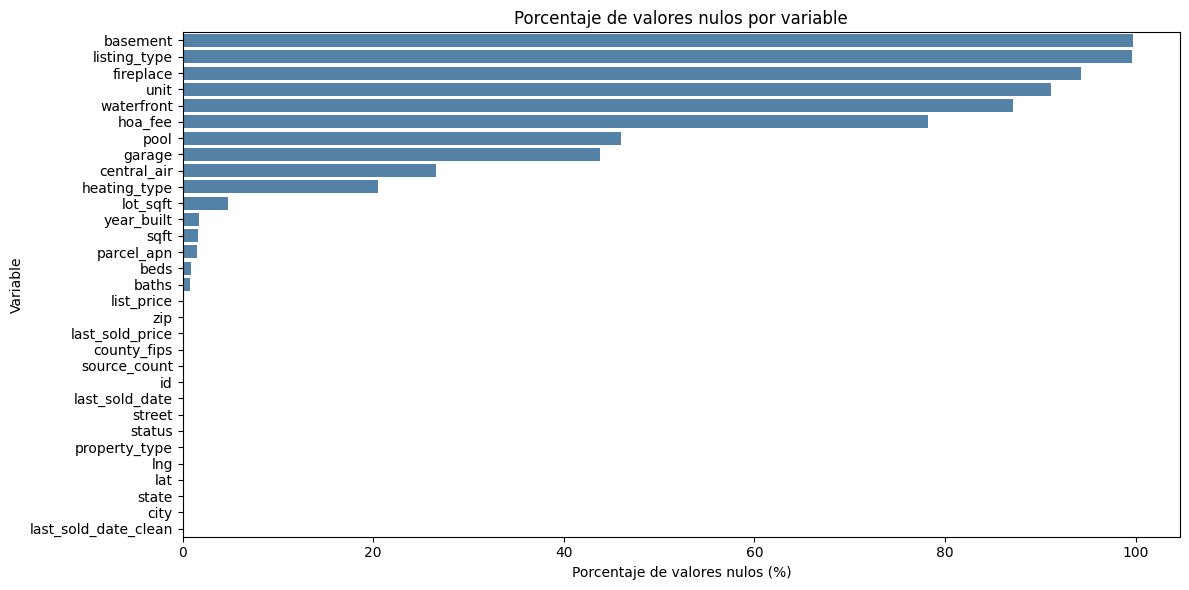

In [57]:

# Representación gráfica del porcentaje de valores nulos

plt.figure(figsize=(12, 6))

sns.barplot(
    data=nulos_final.reset_index(),
    x='Porcentaje nulos',
    y='index',
    color='steelblue'
)

plt.title('Porcentaje de valores nulos por variable')
plt.xlabel('Porcentaje de valores nulos (%)')
plt.ylabel('Variable')
plt.tight_layout()
plt.show()


Vamos a comprobar los valores

In [58]:

variables_revision = [
    'basement',
    'listing_type',
    'fireplace',
    'unit',
    'waterfront',
    'hoa_fee',
    'pool',
    'garage',
    'central_air'
]

for variable in variables_revision:

    print(f'\n--- {variable} ---')
    print('Valores más frecuentes:')
    print(df_limpio_final[variable].value_counts(dropna=False).head(10))



--- basement ---
Valores más frecuentes:
basement
NaN     91568
True      297
Name: count, dtype: int64

--- listing_type ---
Valores más frecuentes:
listing_type
NaN                 91505
new_construction      250
foreclosure            36
fsbo                   22
auction                22
coming_soon            19
bank_owned             11
Name: count, dtype: int64

--- fireplace ---
Valores más frecuentes:
fireplace
NaN     86644
True     5221
Name: count, dtype: int64

--- unit ---
Valores más frecuentes:
unit
NaN       83698
           7743
#1            9
Unit .        5
#2            5
Unit B        3
Unit A        3
#0            3
#151          2
#3425         2
Name: count, dtype: int64

--- waterfront ---
Valores más frecuentes:
waterfront
NaN     80061
True    11804
Name: count, dtype: int64

--- hoa_fee ---
Valores más frecuentes:
hoa_fee
NaN      71882
200.0      318
150.0      303
100.0      292
65.0       277
75.0       264
50.0       246
35.0       232
90.0       229

Comprbamos si existen valores False

In [59]:

variables_booleanas = [
    'basement',
    'fireplace',
    'waterfront',
    'pool',
    'garage',
    'central_air'
]

for variable in variables_booleanas:
    print(f'\n{variable}')
    print(df_limpio_final[variable].value_counts(dropna=False))



basement
basement
NaN     91568
True      297
Name: count, dtype: int64

fireplace
fireplace
NaN     86644
True     5221
Name: count, dtype: int64

waterfront
waterfront
NaN     80061
True    11804
Name: count, dtype: int64

pool
pool
True    49596
NaN     42269
Name: count, dtype: int64

garage
garage
True    51609
NaN     40256
Name: count, dtype: int64

central_air
central_air
True    67398
NaN     24467
Name: count, dtype: int64


In [60]:
for variable in variables_booleanas:
    df_limpio_final[variable] = (
        df_limpio_final[variable].fillna(False)
    )

print("Tratamiento de los valores nulos completado.")

Tratamiento de los valores nulos completado.


Comprobamos si se ha hecho bien la transformación

In [61]:

for variable in variables_booleanas:
    print(f'\n--- {variable} ---')
    print(df_limpio_final[variable].value_counts(dropna=False))

# Comprobamos los nulos restantes en estas variables
print(
    "\nNulos restantes:",
    df_limpio_final[variables_booleanas].isnull().sum().sum()
)



--- basement ---
basement
False    91568
True       297
Name: count, dtype: int64

--- fireplace ---
fireplace
False    86644
True      5221
Name: count, dtype: int64

--- waterfront ---
waterfront
False    80061
True     11804
Name: count, dtype: int64

--- pool ---
pool
True     49596
False    42269
Name: count, dtype: int64

--- garage ---
garage
True     51609
False    40256
Name: count, dtype: int64

--- central_air ---
central_air
True     67398
False    24467
Name: count, dtype: int64

Nulos restantes: 0


### **Tratamiento de valores ausentes en variables booleanas**

Hemos identificado seis variables booleanas que indican si una vivienda dispone de determinadas características: `basement`, `fireplace`, `waterfront`, `pool`, `garage` y `central_air`.

En este conjunto de datos, los valores ausentes de estas variables representan que la vivienda no dispone de la característica correspondiente. Por tanto, hemos sustituido los valores nulos por `False`, manteniendo los valores `True` para aquellas viviendas que sí cuentan con dicha característica.

Tras aplicar esta transformación, hemos comprobado que las seis variables ya no presentan valores ausentes y que únicamente contienen valores `True` o `False`.

Este tratamiento permite homogeneizar la información y facilita la utilización de estas variables en las posteriores fases de análisis y modelización.

Ahora analicemos algunas variables que pueden ser ambiguas 'listing_type', 'unit', 'hoa_fee'

In [62]:
variables_pendientes = ['listing_type', 'unit', 'hoa_fee']

for variable in variables_pendientes:

    print(f'\n--- {variable} ---')

    print(
        'Valores nulos:',
        df_limpio_final[variable].isnull().sum()
    )

    print(
        'Porcentaje nulos:',
        round(df_limpio_final[variable].isnull().mean() * 100, 2),
        '%'
    )

    print('\nValores más frecuentes:')
    print(df_limpio_final[variable].value_counts(dropna=False).head(15))


--- listing_type ---
Valores nulos: 91505
Porcentaje nulos: 99.61 %

Valores más frecuentes:
listing_type
NaN                 91505
new_construction      250
foreclosure            36
fsbo                   22
auction                22
coming_soon            19
bank_owned             11
Name: count, dtype: int64

--- unit ---
Valores nulos: 83698
Porcentaje nulos: 91.11 %

Valores más frecuentes:
unit
NaN           83698
               7743
#1                9
Unit .            5
#2                5
Unit B            3
Unit A            3
#0                3
#151              2
#3425             2
#4                2
#703              2
Unit 1-10         1
Fl 33134          1
Unit 3-114        1
Name: count, dtype: int64

--- hoa_fee ---
Valores nulos: 71882
Porcentaje nulos: 78.25 %

Valores más frecuentes:
hoa_fee
NaN      71882
200.0      318
150.0      303
100.0      292
65.0       277
75.0       264
50.0       246
35.0       232
90.0       229
80.0       228
40.0       223
95.0  

### **Decisión sobre las variables `listing_type`, `unit` y `hoa_fee`**

Tras analizar la distribución y el significado de estas tres variables, hemos decidido aplicar los siguientes tratamientos:

**1. `listing_type`: eliminación**

Esta variable presenta un 99,61 % de valores ausentes. Además, los 360 registros que contienen información están repartidos entre categorías con frecuencias muy reducidas.

Dado su elevado porcentaje de valores ausentes y su limitada capacidad para aportar información al modelo, hemos decidido eliminarla.

**2. `unit`: eliminación**

Esta variable identifica el número o la denominación de una unidad dentro de un inmueble. Al trabajar exclusivamente con viviendas unifamiliares, consideramos que no constituye una característica física relevante para nuestra valoración.

Por este motivo, hemos decidido eliminarla del conjunto de datos.

**3. `hoa_fee`: conservación**

A diferencia de las anteriores, `hoa_fee` es una variable numérica que recoge las cuotas asociadas a la comunidad o asociación de propietarios (*Homeowners Association*).

Aunque presenta un 78,25 % de valores ausentes, hemos decidido conservarla porque puede aportar información relevante sobre los gastos asociados a la vivienda.

No sustituiremos sus valores ausentes por cero, ya que la falta de información sobre la cuota no implica necesariamente que esta no exista.

En consecuencia, eliminamos `listing_type` y `unit`, mientras que mantenemos `hoa_fee` con sus valores ausentes para evitar introducir información no contrastada.

In [63]:

# Variables que hemos decidido eliminar
columnas_eliminar = ['listing_type', 'unit']

# Eliminamos las columnas del dataset
df_limpio_final = df_limpio_final.drop(
    columns=columnas_eliminar
)

print("Columnas eliminadas:", columnas_eliminar)
print("Dimensiones del dataset:", df_limpio_final.shape)


Columnas eliminadas: ['listing_type', 'unit']
Dimensiones del dataset: (91865, 29)


Analizamos hoa_fee

In [64]:

print("Estadísticas de HOA Fee:")
print(df_limpio_final['hoa_fee'].describe())

print("\nCuotas iguales a cero:")
print((df_limpio_final['hoa_fee'] == 0).sum())

print("\nCuotas negativas:")
print((df_limpio_final['hoa_fee'] < 0).sum())

print("\nPorcentaje de valores nulos:")
print(
    round(df_limpio_final['hoa_fee'].isnull().mean() * 100, 2),
    "%"
)


Estadísticas de HOA Fee:
count    19983.000000
mean       243.855978
std        397.031774
min          1.000000
25%         72.000000
50%        148.000000
75%        270.000000
max      12200.000000
Name: hoa_fee, dtype: float64

Cuotas iguales a cero:
0

Cuotas negativas:
0

Porcentaje de valores nulos:
78.25 %


### **Tratamiento de valores ausentes en `hoa_fee`**

La variable `hoa_fee` presenta un 78,25 % de valores ausentes. Hemos decidido conservarla porque puede aportar información relevante sobre los gastos asociados a la propiedad.

No sustituiremos los valores ausentes por cero, ya que no disponer de información sobre la cuota no significa necesariamente que esta no exista.

Para conservar esta distinción, creamos una nueva variable auxiliar, `hoa_fee_available`, que indica si conocemos el importe de la cuota:

- **True:** disponemos de información sobre la cuota HOA.
- **False:** no disponemos de información sobre la cuota HOA.

De esta manera, mantenemos los valores originales de `hoa_fee` y añadimos una variable que permite al modelo identificar cuándo existe información disponible.



In [65]:

# Creamos una variable que indica si conocemos la cuota HOA
df_limpio_final['hoa_fee_available'] = (
    df_limpio_final['hoa_fee'].notna()
)

print(
    df_limpio_final[
        ['hoa_fee', 'hoa_fee_available']
    ].head(10)
)

print("\nDistribución de la nueva variable:")
print(df_limpio_final['hoa_fee_available'].value_counts())


    hoa_fee  hoa_fee_available
12      NaN              False
30      NaN              False
34      NaN              False
36      NaN              False
42      NaN              False
47      NaN              False
75      NaN              False
81      NaN              False
89      NaN              False
94      NaN              False

Distribución de la nueva variable:
hoa_fee_available
False    71882
True     19983
Name: count, dtype: int64


Revisemos el valor áximo de 12.200 para ver si es un dato válido o un posible error.

In [66]:
# Mostramos las 15 viviendas con mayor cuota HOA

df_limpio_final[
    ['street', 'city', 'hoa_fee', 'last_sold_price']
].sort_values(
    'hoa_fee',
    ascending=False
).head(15)

,street,city,hoa_fee,last_sold_price
294567,10515 NE 3rd Ave,Miami Shores,12200.0,750000.0
483359,9774 W 34th Ct,Hialeah,11900.0,485000.0
924775,105 Reef Ln,Key Biscayne,9725.0,5600000.0
972317,1081 W 48th St Unit N01,Miami Beach,9269.0,5800000.0
924774,107 Reef Ln,Key Biscayne,7639.0,9000000.0
972205,4700 N Meridian Ave,Miami Beach,7500.0,5250000.0
85782,6360 N Bay Rd,Miami Beach,6755.0,32000000.0
471202,3437 N Moorings Way,Miami,6650.0,3350000.0
919279,17875 Collins Ave #2704,North Miami Beach,5741.0,3200000.0
979565,6325 Allison Rd,Miami Beach,5730.0,7325000.0


Se observa una distribución asimétrica en la variable hoa_fee, con una mediana de 148 y un valor máximo de 12.200. Algunos registros presentan cuotas considerablemente superiores al resto de observaciones.

Estas diferencias podrían corresponder a propiedades con características particulares o a posibles inconsistencias en los datos. Por tanto, no eliminaremos estos valores automáticamente. Antes de decidir su tratamiento, revisaremos las características de las viviendas con las cuotas más elevadas y comprobaremos si existen posibles anomalías.

In [67]:
# Revisamos las 15 viviendas con mayor cuota HOA

columnas_revision = [
    'street',
    'city',
    'property_type',
    'beds',
    'baths',
    'sqft',
    'lot_sqft',
    'year_built',
    'hoa_fee',
    'last_sold_price'
]

df_limpio_final.nlargest(15, 'hoa_fee')[columnas_revision]

,street,city,property_type,beds,baths,sqft,lot_sqft,year_built,hoa_fee,last_sold_price
294567,10515 NE 3rd Ave,Miami Shores,single_family,4.0,3.0,2119.0,14374.0,1940.0,12200.0,750000.0
483359,9774 W 34th Ct,Hialeah,single_family,5.0,4.0,2433.0,3419.0,2016.0,11900.0,485000.0
924775,105 Reef Ln,Key Biscayne,single_family,7.0,5.5,5000.0,11000.0,2014.0,9725.0,5600000.0
972317,1081 W 48th St Unit N01,Miami Beach,single_family,4.0,4.5,4168.0,NaN,2022.0,9269.0,5800000.0
924774,107 Reef Ln,Key Biscayne,single_family,7.0,5.5,5074.0,10000.0,2014.0,7639.0,9000000.0
972205,4700 N Meridian Ave,Miami Beach,single_family,3.0,3.5,4185.0,10596.0,2021.0,7500.0,5250000.0
85782,6360 N Bay Rd,Miami Beach,single_family,NaN,NaN,NaN,134300.0,2021.0,6755.0,32000000.0
471202,3437 N Moorings Way,Miami,single_family,4.0,6.0,4071.0,12462.0,1935.0,6650.0,3350000.0
919279,17875 Collins Ave #2704,North Miami Beach,single_family,2.0,2.5,2035.0,NaN,2006.0,5741.0,3200000.0
979565,6325 Allison Rd,Miami Beach,single_family,6.0,6.5,4915.0,18641.0,1992.0,5730.0,7325000.0


La revisión de los 15 registros con mayores cuotas HOA muestra que algunos valores elevados corresponden a viviendas de lujo situadas en zonas como Key Biscayne y Miami Beach, por lo que podrían ser razonables.

Sin embargo, otros registros presentan cuotas especialmente elevadas en relación con el precio de venta de la vivienda, como los casos de Miami Shores y Hialeah. Estos registros requieren una comprobación adicional.

También se observan algunas direcciones con identificadores de unidad, a pesar de que el conjunto de datos está filtrado para viviendas unifamiliares.

Por tanto, mantendremos provisionalmente estos valores y no estableceremos un límite máximo arbitrario para eliminar cuotas HOA.


### 1.3.10 Variables principales del modelo

Vamos a analizar las variables que tendrán mayor importancia para estimar el precio de una vivienda.
- beds: número de dormitorios.
- baths: número de baños.
- sqft: superficie construida.
- lot_sqft: superficie de la parcela.
- year_built: año de construcción.

Primero calculamos sus valores nulos, estadisticas descriptivas y valores iguales a 0.

In [68]:

variables_principales = [
    'beds',
    'baths',
    'sqft',
    'lot_sqft',
    'year_built'
]

# Resumen de valores nulos
resumen_principales = pd.DataFrame({
    'Nulos': df_limpio_final[variables_principales].isnull().sum(),
    'Porcentaje nulos': (
        df_limpio_final[variables_principales].isnull().mean() * 100
    ),
    'Valores iguales a cero': (
        df_limpio_final[variables_principales] == 0
    ).sum()
})

print("RESUMEN DE VALORES NULOS Y CEROS")
display(resumen_principales.round(2))

print("\nESTADÍSTICAS DESCRIPTIVAS")
display(df_limpio_final[variables_principales].describe().round(2))


RESUMEN DE VALORES NULOS Y CEROS


,Nulos,Porcentaje nulos,Valores iguales a cero
beds,764,0.83,172
baths,744,0.81,164
sqft,1432,1.56,522
lot_sqft,4374,4.76,897
year_built,1602,1.74,0



ESTADÍSTICAS DESCRIPTIVAS


,beds,baths,sqft,lot_sqft,year_built
count,91101.00,91121.00,90433.00,8.749100e+04,90263.00
mean,3.57,2.56,2076.43,5.933727e+04,1976.32
std,1.02,1.26,1338.29,4.017253e+06,25.99
min,0.00,0.00,0.00,0.000000e+00,1900.00
25%,3.00,2.00,1380.00,5.500000e+03,1954.00
50%,3.00,2.00,1782.00,7.501000e+03,1973.00
75%,4.00,3.00,2399.00,1.000000e+04,1998.00
max,22.00,22.00,56876.00,4.813380e+08,2027.00


### **Interpretación de las variables principales**

El análisis muestra que las variables presentan distintos niveles de calidad y disponibilidad de información:

- **beds y baths:** tienen un porcentaje reducido de valores nulos (0,83 % y 0,81 %, respectivamente). También aparecen algunos registros con valor cero, que deben tratarse como posibles inconsistencias, ya que estamos analizando viviendas unifamiliares.
- **sqft:** presenta un 1,56 % de valores nulos y 522 registros con valor cero. Estos casos requieren revisión, puesto que la superficie construida es una variable fundamental para la valoración.
- **lot_sqft:** tiene un 4,76 % de valores nulos y una dispersión muy elevada. La diferencia entre la mediana (7.501 pies cuadrados) y la media, junto con el valor máximo, refleja la presencia de parcelas de dimensiones muy diferentes y algunos valores extremos. Se conservará la variable sin aplicar eliminaciones adicionales.
- **year_built:** presenta un 1,74 % de valores nulos. La mayoría de las viviendas se concentra alrededor de la década de 1970. Se han identificado algunos años atípicos, como 1900 y 2027, que se han revisado individualmente.

En conjunto, estas variables presentan información suficiente para continuar con el análisis, aunque será necesario mantener un tratamiento específico para los valores ausentes, los ceros y los posibles valores extremos.

Investiguemos los valores iguales a 0.

In [69]:

# Analizamos los registros con valores iguales a cero

for variable in variables_principales:

    registros_cero = df_limpio_final[
        df_limpio_final[variable] == 0
    ]

    print(f'\n--- {variable} ---')
    print("Número de registros:", len(registros_cero))

    if len(registros_cero) > 0:
        display(
            registros_cero[
                [
                    'street',
                    'city',
                    'beds',
                    'baths',
                    'sqft',
                    'lot_sqft',
                    'year_built',
                    'last_sold_price'
                ]
            ].head(10)
        )



--- beds ---
Número de registros: 172


,street,city,beds,baths,sqft,lot_sqft,year_built,last_sold_price
13008,6415 NW 1st Pl,Miami,0.0,0.0,0.0,126324.0,NaN,3900000.0
37287,2536 W 8th Ln,Hialeah,0.0,0.0,1050.0,5501.0,1962.0,299300.0
51476,14225 N Miami Ave,Miami,0.0,0.0,1395.0,21158.0,1957.0,500000.0
51595,13540 NW 1st Ave,Miami,0.0,1.0,180.0,NaN,NaN,335000.0
56705,900 Bay Dr #DS26,Miami Beach,0.0,0.0,247.0,NaN,1963.0,150000.0
84837,5225 Collins Ave #CU105,Miami Beach,0.0,1.0,150.0,NaN,1962.0,175000.0
95194,2675 Flamingo Dr,Miami Beach,0.0,0.0,484.0,22651.0,1937.0,2900000.0
98561,6902 SW 83rd Pl,Miami,0.0,1.0,NaN,NaN,2004.0,785000.0
109903,6770 Indian Creek Drive Cu #35,Miami Beach,0.0,0.0,NaN,NaN,1968.0,80000.0
135887,1505 NE 141st St,North Miami,0.0,1.0,450.0,NaN,NaN,430000.0



--- baths ---
Número de registros: 164


,street,city,beds,baths,sqft,lot_sqft,year_built,last_sold_price
13008,6415 NW 1st Pl,Miami,0.0,0.0,0.0,126324.0,NaN,3900000.0
37287,2536 W 8th Ln,Hialeah,0.0,0.0,1050.0,5501.0,1962.0,299300.0
51476,14225 N Miami Ave,Miami,0.0,0.0,1395.0,21158.0,1957.0,500000.0
55947,611 86th St,Miami Beach,NaN,0.0,2137.0,6969.0,1951.0,1050000.0
56705,900 Bay Dr #DS26,Miami Beach,0.0,0.0,247.0,NaN,1963.0,150000.0
57138,6596 Allison Rd,Miami Beach,NaN,0.0,2265.0,NaN,2019.0,51000000.0
57163,6455 Pine Tree Dr,Miami Beach,NaN,0.0,13566.0,27860.0,2019.0,20000000.0
79436,100 NE 116th St,Miami,NaN,0.0,4173.0,14374.0,1950.0,145000.0
82404,611 NE 4th Pl,Hialeah,NaN,0.0,1889.0,6359.0,1947.0,240000.0
90716,14900 SW 179th St,Miami,NaN,0.0,4121.0,93218.0,1971.0,266000.0



--- sqft ---
Número de registros: 522


,street,city,beds,baths,sqft,lot_sqft,year_built,last_sold_price
13008,6415 NW 1st Pl,Miami,0.0,0.0,0.0,126324.0,NaN,3900000.0
30211,2240 NW 152nd St,Opa Locka,4.0,3.0,0.0,6000.0,2025.0,570000.0
55582,1240 N Biscayne Point Rd,Miami Beach,4.0,4.0,0.0,12900.0,2025.0,473000.0
85695,5900 Collins Ave APT 2203,Miami Beach,2.0,2.0,0.0,NaN,1998.0,641000.0
85766,5900 Collins Ave APT 608,Miami Beach,3.0,2.0,0.0,NaN,1998.0,750000.0
119246,1340 Lincoln Rd APT 502,Miami Beach,1.0,2.0,0.0,NaN,1969.0,290000.0
176032,9971 W Bay Harbor Dr APT 105,Bay Harbor Islands,1.0,2.0,0.0,NaN,1966.0,176000.0
198480,3540 Main Hwy #308,Miami,2.0,3.0,0.0,NaN,2006.0,700000.0
224607,50 S Pointe Dr #Twn1,Miami Beach,3.0,4.0,0.0,NaN,2008.0,5500000.0
233079,1889 NW 63rd St,Miami,3.0,2.0,0.0,6027.0,2021.0,390000.0



--- lot_sqft ---
Número de registros: 897


,street,city,beds,baths,sqft,lot_sqft,year_built,last_sold_price
320,3900 NW 175th St,Miami Gardens,3.0,2.0,NaN,0.0,1954.0,402000.0
6513,1075 NW 53rd St,Miami,4.0,2.0,1600.0,0.0,2022.0,461000.0
7078,1511 NW 49th St,Miami,4.0,2.0,1367.0,0.0,1958.0,465000.0
7356,825 NW 43rd St,Miami,4.0,2.0,NaN,0.0,1965.0,510000.0
9938,1375 NW 182nd St,Miami Gardens,3.0,2.0,1056.0,0.0,1957.0,458000.0
23106,10521 SW 143rd Ave,Miami,3.0,2.0,2122.0,0.0,1987.0,455000.0
26254,6541 SW 164th Ct,Miami,3.0,3.0,2623.0,0.0,2003.0,720000.0
26875,1265 W 38th St,Hialeah,3.0,2.0,1198.0,0.0,1980.0,420000.0
29751,2455 NW 159th Ter,Miami Gardens,4.0,2.0,NaN,0.0,1951.0,395000.0
32769,11501 SW 131st Ave,Miami,4.0,3.0,NaN,0.0,1979.0,810000.0



--- year_built ---
Número de registros: 0


Investigamos valores extremos

In [70]:

# Calculamos percentiles para detectar valores extremos

for variable in variables_principales:

    print(f'\n--- {variable} ---')

    print(
        df_limpio_final[variable].quantile(
            [0.01, 0.05, 0.50, 0.90, 0.95, 0.99, 0.999]
        )
    )



--- beds ---
0.010    2.0
0.050    2.0
0.500    3.0
0.900    5.0
0.950    5.0
0.990    7.0
0.999    9.0
Name: beds, dtype: float64

--- baths ---
0.010     1.0
0.050     1.0
0.500     2.0
0.900     4.0
0.950     5.0
0.990     7.5
0.999    11.0
Name: baths, dtype: float64

--- sqft ---
0.010      600.000
0.050      953.600
0.500     1782.000
0.900     3232.000
0.950     4093.400
0.990     7000.000
0.999    13404.176
Name: sqft, dtype: float64

--- lot_sqft ---
0.010         0.0
0.050      3223.0
0.500      7501.0
0.900     16199.0
0.950     25925.5
0.990     94524.1
0.999    609840.0
Name: lot_sqft, dtype: float64

--- year_built ---
0.010    1925.0
0.050    1939.0
0.500    1973.0
0.900    2016.0
0.950    2021.0
0.990    2024.0
0.999    2026.0
Name: year_built, dtype: float64


### **Interpretación de los valores extremos**

El análisis de percentiles permite identificar diferencias importantes en la distribución de las variables principales.

Las variables `beds` y `baths` presentan valores elevados poco frecuentes, aunque no necesariamente incorrectos, ya que pueden corresponder a viviendas de grandes dimensiones.

La variable `sqft` también presenta una distribución asimétrica, con una diferencia considerable entre la mediana y los percentiles superiores. Por ello, revisaremos las viviendas con superficies construidas excepcionalmente elevadas.

Por su parte, `lot_sqft` presenta la mayor dispersión, con valores extremos que podrían corresponder a parcelas de grandes dimensiones o a posibles inconsistencias en los datos.

Finalmente, `year_built` muestra una distribución concentrada principalmente en viviendas construidas durante la segunda mitad del siglo XX.

No eliminaremos automáticamente los valores extremos por superar determinados percentiles. Revisaremos los casos más destacados para distinguir entre propiedades excepcionales y posibles errores de registro.


In [71]:
# Convertimos ceros en nulos
# Variables en las que un valor cero no representa
# una característica válida de la vivienda

variables_cero_a_nulo = [
    'beds',
    'baths',
    'sqft',
    'lot_sqft'
]

# Sustituimos los ceros por valores nulos
for variable in variables_cero_a_nulo:
    df_limpio_final[variable] = (
        df_limpio_final[variable].replace(0, np.nan)
    )

# Comprobamos los resultados
print("Valores nulos después del tratamiento:\n")

print(
    df_limpio_final[
        variables_cero_a_nulo
    ].isnull().sum()
)


Valores nulos después del tratamiento:

beds         936
baths        908
sqft        1954
lot_sqft    5271
dtype: int64


Investigamos valores extremos

In [72]:

# Revisamos las 15 viviendas con mayor superficie construida
print("MAYORES SUPERFICIES CONSTRUIDAS")

display(
    df_limpio_final.nlargest(15, 'sqft')[
        [
            'street',
            'city',
            'beds',
            'baths',
            'sqft',
            'lot_sqft',
            'year_built',
            'last_sold_price'
        ]
    ]
)

# Revisamos las 15 viviendas con mayor superficie de parcela
print("MAYORES SUPERFICIES DE PARCELA")

display(
    df_limpio_final.nlargest(15, 'lot_sqft')[
        [
            'street',
            'city',
            'beds',
            'baths',
            'sqft',
            'lot_sqft',
            'year_built',
            'last_sold_price'
        ]
    ]
)


MAYORES SUPERFICIES CONSTRUIDAS


,street,city,beds,baths,sqft,lot_sqft,year_built,last_sold_price
702167,15155 SW 97th Ave,Miami,NaN,NaN,56876.0,143734.0,2021.0,7550000.0
434611,8601 NW 27th St,Doral,NaN,NaN,52122.0,102627.0,2015.0,11450000.0
100004,1500 Douglas Rd #CU1-5,Miami,NaN,NaN,45985.0,NaN,1994.0,370000.0
210656,3010 Collins Ave,Miami Beach,NaN,NaN,43602.0,12000.0,1939.0,33000000.0
725156,3500 Nw 71st St,Miami,NaN,NaN,43000.0,NaN,NaN,5620000.0
538748,217 N Krome Ave,Florida City,NaN,NaN,41464.0,42767.0,2020.0,5300000.0
702172,12750 SW 128th St,Miami,NaN,NaN,40840.0,185400.0,2020.0,26000000.0
459522,3338 NE 7th St,Homestead,NaN,NaN,40715.0,322914.0,2017.0,22713700.0
305011,14880 SW 26th St,Miami,NaN,NaN,39395.0,71194.0,2011.0,1350000.0
423366,29055 SW 107th Ave,Homestead,NaN,NaN,35796.0,219193.0,2015.0,2500000.0


MAYORES SUPERFICIES DE PARCELA


,street,city,beds,baths,sqft,lot_sqft,year_built,last_sold_price
55783,675 N Shore Dr,Miami Beach,4.0,5.0,3418.0,481338000.0,1953.0,2500000.0
147218,13105 NE 13th Avenue,North Miami,3.0,2.0,1392.0,447579000.0,1949.0,355000.0
245664,7891 SW 67th Ave,South Miami,3.0,2.0,1712.0,436993920.0,1950.0,633000.0
95237,3350 Flamingo Dr,Miami Beach,4.0,3.0,2599.0,435600000.0,1951.0,3750000.0
108454,280 N Hibiscus Dr,Miami Beach,5.0,4.0,NaN,413820000.0,NaN,2525000.0
255288,620 NW 15th St,Homestead,1.0,1.0,578.0,283140000.0,1944.0,155000.0
91315,15081 SW 170th Ter,Miami,3.0,2.0,2069.0,261360000.0,1996.0,375000.0
358168,420 NW 30th Pl,Miami,3.0,2.0,1830.0,261360000.0,1954.0,510000.0
335004,616 SW 73rd Ave,Miami,4.0,3.0,1526.0,239580000.0,1925.0,410000.0
654875,14542 NW 88th Pl,Miami Lakes,4.0,3.0,2236.0,218148480.0,1998.0,600000.0


### **Tratamiento de valores extremos en las superficies**

Tras analizar los valores extremos de las variables `sqft` y `lot_sqft`, establecemos los siguientes criterios:

- **`sqft` (superficie construida):** se identificaron 21 registros con superficies superiores a 20.000 pies cuadrados que, además, no disponían de información sobre dormitorios ni baños. Se decidió eliminar estos registros por la falta de información que permitiera contrastar sus características. Se conservaron otros registros con superficies elevadas cuando presentaban información suficiente para considerarlos potencialmente válidos.

- **`lot_sqft` (superficie de parcela):** se detectaron valores extraordinariamente elevados, algunos superiores a 4.000 millones de pies cuadrados. No obstante, se decidió conservarlos provisionalmente, sin eliminar registros de forma automática. Estas observaciones quedan identificadas como posibles anomalías que deberán tenerse en cuenta en futuras fases del proyecto.

En ambos casos, se prioriza evitar la eliminación injustificada de viviendas que puedan representar operaciones inmobiliarias reales.

In [73]:

# Analizamos los percentiles de la superficie construida

print("Percentiles de sqft:")
display(
    df_limpio_final['sqft'].quantile(
        [0.50, 0.75, 0.90, 0.95, 0.99, 0.995, 0.999, 1]
    )
)

# Mostramos las 20 viviendas con mayor superficie construida

print("\n20 mayores superficies construidas:")

display(
    df_limpio_final.nlargest(20, 'sqft')[
        [
            'street',
            'city',
            'beds',
            'baths',
            'sqft',
            'lot_sqft',
            'year_built',
            'last_sold_price'
        ]
    ]
)


Percentiles de sqft:


0.500     1788.00
0.750     2401.00
0.900     3239.00
0.950     4101.50
0.990     7010.60
0.995     8596.45
0.999    13420.61
1.000    56876.00
Name: sqft, dtype: float64


20 mayores superficies construidas:


,street,city,beds,baths,sqft,lot_sqft,year_built,last_sold_price
702167,15155 SW 97th Ave,Miami,NaN,NaN,56876.0,143734.0,2021.0,7550000.0
434611,8601 NW 27th St,Doral,NaN,NaN,52122.0,102627.0,2015.0,11450000.0
100004,1500 Douglas Rd #CU1-5,Miami,NaN,NaN,45985.0,NaN,1994.0,370000.0
210656,3010 Collins Ave,Miami Beach,NaN,NaN,43602.0,12000.0,1939.0,33000000.0
725156,3500 Nw 71st St,Miami,NaN,NaN,43000.0,NaN,NaN,5620000.0
538748,217 N Krome Ave,Florida City,NaN,NaN,41464.0,42767.0,2020.0,5300000.0
702172,12750 SW 128th St,Miami,NaN,NaN,40840.0,185400.0,2020.0,26000000.0
459522,3338 NE 7th St,Homestead,NaN,NaN,40715.0,322914.0,2017.0,22713700.0
305011,14880 SW 26th St,Miami,NaN,NaN,39395.0,71194.0,2011.0,1350000.0
423366,29055 SW 107th Ave,Homestead,NaN,NaN,35796.0,219193.0,2015.0,2500000.0


Identificamos los registros con más de 20,000 sqft.
Quiero comprobar cuántos tienen info de dormitorios y baños y cuantos carecen de ambas variables.

In [74]:

# Seleccionamos viviendas con más de 20.000 sqft
sqft_extremos = df_limpio_final[
    df_limpio_final['sqft'] > 20000
].copy()

print("Viviendas con más de 20.000 sqft:", len(sqft_extremos))

print(
    "\nSin información de dormitorios y baños:",
    (
        sqft_extremos['beds'].isna() &
        sqft_extremos['baths'].isna()
    ).sum()
)

print(
    "\nCon información de dormitorios y baños:",
    (
        sqft_extremos['beds'].notna() &
        sqft_extremos['baths'].notna()
    ).sum()
)

print("\nDistribución de dormitorios y baños:")
display(
    sqft_extremos[
        ['street', 'city', 'beds', 'baths', 'sqft', 'last_sold_price']
    ].sort_values('sqft', ascending=False)
)


Viviendas con más de 20.000 sqft: 26

Sin información de dormitorios y baños: 21

Con información de dormitorios y baños: 5

Distribución de dormitorios y baños:


,street,city,beds,baths,sqft,last_sold_price
702167,15155 SW 97th Ave,Miami,NaN,NaN,56876.0,7550000.0
434611,8601 NW 27th St,Doral,NaN,NaN,52122.0,11450000.0
100004,1500 Douglas Rd #CU1-5,Miami,NaN,NaN,45985.0,370000.0
210656,3010 Collins Ave,Miami Beach,NaN,NaN,43602.0,33000000.0
725156,3500 Nw 71st St,Miami,NaN,NaN,43000.0,5620000.0
538748,217 N Krome Ave,Florida City,NaN,NaN,41464.0,5300000.0
702172,12750 SW 128th St,Miami,NaN,NaN,40840.0,26000000.0
459522,3338 NE 7th St,Homestead,NaN,NaN,40715.0,22713700.0
305011,14880 SW 26th St,Miami,NaN,NaN,39395.0,1350000.0
423366,29055 SW 107th Ave,Homestead,NaN,NaN,35796.0,2500000.0


De los 26 registros identificados, eliminaremos los 21 que no disponen de información ni de dormitorios ni de baños. Conservaremos los otros 5, ya que cuentan con información sobre ambas características y podrían representar viviendas de grandes dimensiones perfectamente válidas.


In [75]:

# Identificamos las viviendas que vamos a eliminar
condicion_eliminar = (
    (df_limpio_final['sqft'] > 20000) &
    (df_limpio_final['beds'].isna()) &
    (df_limpio_final['baths'].isna())
)

# Eliminamos únicamente esos registros
df_limpio_final = df_limpio_final[
    ~condicion_eliminar
].copy()

print("Registros eliminados:", condicion_eliminar.sum())
print("Registros restantes:", len(df_limpio_final))


Registros eliminados: 21
Registros restantes: 91844


Ahora comprobaremos los valores extremos restantes de sqft, para ver si estas viviendas tienen sentido conservarlas.

In [76]:
# Comprobamos las superficies superiores a 20.000 sqft
sqft_restantes = df_limpio_final[
    df_limpio_final['sqft'] > 20000
]

print("Registros restantes:", len(sqft_restantes))

display(
    sqft_restantes[
        [
            'street',
            'city',
            'beds',
            'baths',
            'sqft',
            'last_sold_price'
        ]
    ].sort_values('sqft', ascending=False)
)

Registros restantes: 5


,street,city,beds,baths,sqft,last_sold_price
983991,7 Indian Creek Island Rd,Indian Creek,9.0,13.0,27889.0,170000000.0
670970,27367 Sw133 Court,Homestead,5.0,3.0,23000.0,431990.0
198768,975 NW 95th St,Miami,2.0,1.0,21255.0,4700000.0
311436,4445 Sabal Palm Rd,Miami,12.0,12.0,20567.0,85200000.0
1010006,6555 SW 102nd St,Pinecrest,14.0,14.0,20182.0,19500000.0


### Tratamiento de valores extremos en `sqft`

Durante el análisis de la superficie construida (`sqft`), se identificaron registros con valores superiores a 20.000 sqft.

Tras revisar estos registros, se decidió:

- **Eliminar 21 registros** que presentaban superficies superiores a 20.000 sqft y no disponían de información sobre dormitorios (`beds`) ni baños (`baths`), al considerarse registros poco fiables para el objetivo del proyecto.
- **Conservar 5 registros** que superaban dicho umbral, ya que sus características fueron contrastadas con información inmobiliaria externa y se confirmó que correspondían a propiedades reales.

Esta decisión permite eliminar observaciones potencialmente inconsistentes sin descartar viviendas excepcionales que contienen información válida.

Se priorizó la validación de los datos frente a la eliminación automática de valores extremos mediante criterios estadísticos.

Tras aplicar este criterio, el conjunto de datos queda formado por 91.844 registros. Se conservan las cinco viviendas con superficies superiores a 20.000 sqft, al disponer de información suficiente y haber sido contrastadas externamente.

### 1.3.11 Analizamos la distribuciión de lot_sqft

Recordemos que anteriormente encontramos:
- 4.374 valores nulos (4,76 %).
- 897 valores iguales a cero, que ya convertimos en nulos.
- Una mediana de 7.501 sqft.
- Un máximo de 481.338.000 sqft.
Ese máximo es extraordinariamente elevado y necesitamos investigar si se trata de un error.

In [77]:

# Analizamos los percentiles de la superficie de parcela

print("Percentiles de lot_sqft:")

display(
    df_limpio_final['lot_sqft'].quantile(
        [0.50, 0.75, 0.90, 0.95, 0.99, 0.995, 0.999, 1]
    )
)

# Mostramos las 20 viviendas con mayor superficie de parcela

print("\n20 mayores superficies de parcela:")

display(
    df_limpio_final.nlargest(20, 'lot_sqft')[
        [
            'street',
            'city',
            'beds',
            'baths',
            'sqft',
            'lot_sqft',
            'year_built',
            'last_sold_price'
        ]
    ]
)


Percentiles de lot_sqft:


0.500    7.501000e+03
0.750    1.000000e+04
0.900    1.624160e+04
0.950    2.624900e+04
0.990    9.466201e+04
0.995    2.047320e+05
0.999    6.157362e+05
1.000    4.813380e+08
Name: lot_sqft, dtype: float64


20 mayores superficies de parcela:


,street,city,beds,baths,sqft,lot_sqft,year_built,last_sold_price
55783,675 N Shore Dr,Miami Beach,4.0,5.0,3418.0,481338000.0,1953.0,2500000.0
147218,13105 NE 13th Avenue,North Miami,3.0,2.0,1392.0,447579000.0,1949.0,355000.0
245664,7891 SW 67th Ave,South Miami,3.0,2.0,1712.0,436993920.0,1950.0,633000.0
95237,3350 Flamingo Dr,Miami Beach,4.0,3.0,2599.0,435600000.0,1951.0,3750000.0
108454,280 N Hibiscus Dr,Miami Beach,5.0,4.0,NaN,413820000.0,NaN,2525000.0
255288,620 NW 15th St,Homestead,1.0,1.0,578.0,283140000.0,1944.0,155000.0
91315,15081 SW 170th Ter,Miami,3.0,2.0,2069.0,261360000.0,1996.0,375000.0
358168,420 NW 30th Pl,Miami,3.0,2.0,1830.0,261360000.0,1954.0,510000.0
335004,616 SW 73rd Ave,Miami,4.0,3.0,1526.0,239580000.0,1925.0,410000.0
654875,14542 NW 88th Pl,Miami Lakes,4.0,3.0,2236.0,218148480.0,1998.0,600000.0


In [78]:

# Seleccionamos las 30 parcelas más grandes
lotes_extremos = df_limpio_final.nlargest(
    30, 'lot_sqft'
).copy()

# Convertimos la superficie de la parcela a acres
# 1 acre = 43.560 sqft
lotes_extremos['lot_acres'] = (
    lotes_extremos['lot_sqft'] / 43560
)

# Calculamos la relación entre parcela y superficie construida
lotes_extremos['ratio_lote_vivienda'] = (
    lotes_extremos['lot_sqft'] / lotes_extremos['sqft']
)

# Mostramos los resultados
display(
    lotes_extremos[
        [
            'street',
            'city',
            'sqft',
            'lot_sqft',
            'lot_acres',
            'ratio_lote_vivienda',
            'beds',
            'baths',
            'last_sold_price'
        ]
    ].round(2)
)


,street,city,sqft,lot_sqft,lot_acres,ratio_lote_vivienda,beds,baths,last_sold_price
55783,675 N Shore Dr,Miami Beach,3418.0,481338000.0,11050.00,140824.46,4.0,5.0,2500000.0
147218,13105 NE 13th Avenue,North Miami,1392.0,447579000.0,10275.00,321536.64,3.0,2.0,355000.0
245664,7891 SW 67th Ave,South Miami,1712.0,436993920.0,10032.00,255253.46,3.0,2.0,633000.0
95237,3350 Flamingo Dr,Miami Beach,2599.0,435600000.0,10000.00,167602.92,4.0,3.0,3750000.0
108454,280 N Hibiscus Dr,Miami Beach,NaN,413820000.0,9500.00,NaN,5.0,4.0,2525000.0
255288,620 NW 15th St,Homestead,578.0,283140000.0,6500.00,489861.59,1.0,1.0,155000.0
91315,15081 SW 170th Ter,Miami,2069.0,261360000.0,6000.00,126321.89,3.0,2.0,375000.0
358168,420 NW 30th Pl,Miami,1830.0,261360000.0,6000.00,142819.67,3.0,2.0,510000.0
335004,616 SW 73rd Ave,Miami,1526.0,239580000.0,5500.00,156998.69,4.0,3.0,410000.0
654875,14542 NW 88th Pl,Miami Lakes,2236.0,218148480.0,5008.00,97561.93,4.0,3.0,600000.0


**Conclusión del análisis de lot_sqft**

El análisis confirma la presencia de valores extraordinariamente elevados en la superficie de las parcelas. Algunos registros presentan extensiones de miles de acres, que resultan poco habituales en relación con la superficie construida de las viviendas asociadas.

Estos valores podrían deberse a errores de registro, problemas de formato o a características particulares de determinadas parcelas. Sin embargo, no podemos confirmar que sean incorrectos únicamente a partir de su magnitud.

Por este motivo, se decide conservar provisionalmente todos los registros de lot_sqft, sin aplicar eliminaciones automáticas. Se documenta esta incidencia para tenerla en cuenta en las siguientes fases del proyecto y valorar su impacto en el modelo predictivo.

In [79]:

# Identificamos las superficies de parcela más repetidas
superficies_repetidas = (
    df_limpio_final['lot_sqft']
    .value_counts()
    .loc[lambda x: x > 1]
    .head(15)
)

print("Superficies de parcela repetidas:")
display(superficies_repetidas)

# Revisamos los registros asociados a esas superficies
valores_repetidos = superficies_repetidas.index

display(
    df_limpio_final[
        df_limpio_final['lot_sqft'].isin(valores_repetidos)
    ][
        [
            'parcel_apn',
            'street',
            'city',
            'sqft',
            'lot_sqft',
            'beds',
            'baths',
            'last_sold_price'
        ]
    ].sort_values('lot_sqft', ascending=False).head(40)
)


Superficies de parcela repetidas:


lot_sqft
7500.0     4362
5000.0     2779
7501.0     1346
6000.0     1104
7875.0     1079
8250.0      881
7000.0      595
8000.0      533
5250.0      503
10000.0     494
5500.0      490
15000.0     486
9000.0      414
6750.0      392
4500.0      375
Name: count, dtype: int64

,parcel_apn,street,city,sqft,lot_sqft,beds,baths,last_sold_price
916771,2452050110410,200 Knollwood Dr,Key Biscayne,4657.0,15000.0,7.0,7.5,11450000.0
952299,3050200300500,10080 SW 145th St,Miami,3661.0,15000.0,5.0,4.0,1315000.0
208625,3069020110280.0,18600 SW 127th Pl,Miami,2475.0,15000.0,4.0,3.0,570000.0
951660,3050070560040,11860 SW 112th Ave Cir,Miami,3154.0,15000.0,4.0,4.0,1335000.0
951661,3050070560030,11840 SW 112th Ave Cir,Miami,2409.0,15000.0,4.0,3.0,1050000.0
951872,3050300080240,10820 SW 154th St,Miami,1979.0,15000.0,3.0,2.0,560000.0
951873,3050300080360,10865 SW 152nd Ter,Miami,1620.0,15000.0,4.0,2.0,595000.0
952249,3050200210940,13920 SW 107th Ave,Miami,3010.0,15000.0,4.0,3.0,1395000.0
952250,3050200211500,10521 SW 139th St,Miami,2811.0,15000.0,4.0,3.0,1140000.0
952304,3050200300370,10060 SW 144th St,Miami,3636.0,15000.0,5.0,3.0,1380000.0


Esto no indica que haya duplicados incorrectos. Es normal que muchas viviendas tengan parcelas de dimensiones similares, especialmente en urbanizaciones con terrenos estandarizados.

Lo interesante es que los valores de varios millones de sqft que vimos anteriormente no aparecen entre los más repetidos. Por tanto, parecen casos aislados.

Vamos a identificar las parcelas superiores a 100.000 sqft

In [80]:

# Identificamos parcelas superiores a 100.000 sqft

condicion_lotes_grandes = df_limpio_final['lot_sqft'] > 100000

print(
    "Registros con lot_sqft > 100.000:",
    condicion_lotes_grandes.sum()
)

# Mostramos sus características
display(
    df_limpio_final.loc[
        condicion_lotes_grandes,
        [
            'parcel_apn',
            'street',
            'city',
            'beds',
            'baths',
            'sqft',
            'lot_sqft',
            'year_built',
            'last_sold_price'
        ]
    ].sort_values('lot_sqft', ascending=False).head(40)
)


Registros con lot_sqft > 100.000: 801


,parcel_apn,street,city,beds,baths,sqft,lot_sqft,year_built,last_sold_price
55783,0232030072630,675 N Shore Dr,Miami Beach,4.0,5.0,3418.0,481338000.0,1953.0,2500000.0
147218,622290230550.0,13105 NE 13th Avenue,North Miami,3.0,2.0,1392.0,447579000.0,1949.0,355000.0
245664,940360100210.0,7891 SW 67th Ave,South Miami,3.0,2.0,1712.0,436993920.0,1950.0,633000.0
95237,232260020700.0,3350 Flamingo Dr,Miami Beach,4.0,3.0,2599.0,435600000.0,1951.0,3750000.0
108454,232320050390.0,280 N Hibiscus Dr,Miami Beach,5.0,4.0,NaN,413820000.0,NaN,2525000.0
255288,1078120200030.0,620 NW 15th St,Homestead,1.0,1.0,578.0,283140000.0,1944.0,155000.0
358168,141040050270.0,420 NW 30th Pl,Miami,3.0,2.0,1830.0,261360000.0,1954.0,510000.0
91315,3059330100060.0,15081 SW 170th Ter,Miami,3.0,2.0,2069.0,261360000.0,1996.0,375000.0
335004,140020032750.0,616 SW 73rd Ave,Miami,4.0,3.0,1526.0,239580000.0,1925.0,410000.0
654875,3220210230290,14542 NW 88th Pl,Miami Lakes,4.0,3.0,2236.0,218148480.0,1998.0,600000.0


In [81]:

# Analizamos las parcelas superiores a 100.000 sqft

lotes_grandes = df_limpio_final[
    df_limpio_final['lot_sqft'] > 100000
].copy()

# Calculamos a cuántos acres equivale cada parcela
lotes_grandes['acres'] = (
    lotes_grandes['lot_sqft'] / 43560
)

# Comprobamos si el valor equivale a un número entero de acres
lotes_grandes['acres_enteros'] = (
    (lotes_grandes['acres'] - lotes_grandes['acres'].round()).abs()
    < 0.000001
)

print("Total de parcelas superiores a 100.000 sqft:",
      len(lotes_grandes))

print("Parcelas que equivalen a acres enteros:",
      lotes_grandes['acres_enteros'].sum())

print("Porcentaje de parcelas que equivalen a acres enteros:",
      round(lotes_grandes['acres_enteros'].mean() * 100, 2), "%")

display(
    lotes_grandes[
        [
            'street',
            'city',
            'sqft',
            'lot_sqft',
            'acres',
            'acres_enteros',
            'last_sold_price'
        ]
    ].sort_values('lot_sqft', ascending=False).head(30)
)


Total de parcelas superiores a 100.000 sqft: 801
Parcelas que equivalen a acres enteros: 195
Porcentaje de parcelas que equivalen a acres enteros: 24.34 %


,street,city,sqft,lot_sqft,acres,acres_enteros,last_sold_price
55783,675 N Shore Dr,Miami Beach,3418.0,481338000.0,11050.00000,True,2500000.0
147218,13105 NE 13th Avenue,North Miami,1392.0,447579000.0,10275.00000,True,355000.0
245664,7891 SW 67th Ave,South Miami,1712.0,436993920.0,10032.00000,True,633000.0
95237,3350 Flamingo Dr,Miami Beach,2599.0,435600000.0,10000.00000,True,3750000.0
108454,280 N Hibiscus Dr,Miami Beach,NaN,413820000.0,9500.00000,True,2525000.0
255288,620 NW 15th St,Homestead,578.0,283140000.0,6500.00000,True,155000.0
358168,420 NW 30th Pl,Miami,1830.0,261360000.0,6000.00000,True,510000.0
91315,15081 SW 170th Ter,Miami,2069.0,261360000.0,6000.00000,True,375000.0
335004,616 SW 73rd Ave,Miami,1526.0,239580000.0,5500.00000,True,410000.0
654875,14542 NW 88th Pl,Miami Lakes,2236.0,218148480.0,5008.00000,True,600000.0


In [82]:

# Analizamos la distribución de las parcelas superiores a 100.000 sqft

lotes_grandes = df_limpio_final[
    df_limpio_final['lot_sqft'] > 100000
].copy()

rangos_lotes = pd.cut(
    lotes_grandes['lot_sqft'],
    bins=[100000, 500000, 1000000, 5000000, 10000000, float('inf')],
    labels=[
        '100.000 - 500.000',
        '500.000 - 1.000.000',
        '1.000.000 - 5.000.000',
        '5.000.000 - 10.000.000',
        'Más de 10.000.000'
    ]
)

print("Distribución por rangos de superficie:")
display(rangos_lotes.value_counts().sort_index())

print("\nPorcentaje por rango:")
display(
    (rangos_lotes.value_counts(normalize=True).sort_index() * 100).round(2)
)


Distribución por rangos de superficie:


lot_sqft
100.000 - 500.000         709
500.000 - 1.000.000        28
1.000.000 - 5.000.000      49
5.000.000 - 10.000.000      1
Más de 10.000.000          14
Name: count, dtype: int64


Porcentaje por rango:


lot_sqft
100.000 - 500.000         88.51
500.000 - 1.000.000        3.50
1.000.000 - 5.000.000      6.12
5.000.000 - 10.000.000     0.12
Más de 10.000.000          1.75
Name: proportion, dtype: float64

Vamos a investigar los 14 registros mas extremos

In [83]:

# Viviendas con parcelas superiores a 10 millones de sqft

columnas_revision = [
    'parcel_apn',
    'street',
    'city',
    'beds',
    'baths',
    'sqft',
    'lot_sqft',
    'year_built',
    'last_sold_price'
]

lotes_muy_grandes = (
    df_limpio_final[
        df_limpio_final['lot_sqft'] > 10_000_000
    ][columnas_revision]
    .sort_values('lot_sqft', ascending=False)
)

display(lotes_muy_grandes)


,parcel_apn,street,city,beds,baths,sqft,lot_sqft,year_built,last_sold_price
55783,0232030072630,675 N Shore Dr,Miami Beach,4.0,5.0,3418.0,481338000.0,1953.0,2500000.0
147218,622290230550.0,13105 NE 13th Avenue,North Miami,3.0,2.0,1392.0,447579000.0,1949.0,355000.0
245664,940360100210.0,7891 SW 67th Ave,South Miami,3.0,2.0,1712.0,436993920.0,1950.0,633000.0
95237,232260020700.0,3350 Flamingo Dr,Miami Beach,4.0,3.0,2599.0,435600000.0,1951.0,3750000.0
108454,232320050390.0,280 N Hibiscus Dr,Miami Beach,5.0,4.0,NaN,413820000.0,NaN,2525000.0
255288,1078120200030.0,620 NW 15th St,Homestead,1.0,1.0,578.0,283140000.0,1944.0,155000.0
91315,3059330100060.0,15081 SW 170th Ter,Miami,3.0,2.0,2069.0,261360000.0,1996.0,375000.0
358168,141040050270.0,420 NW 30th Pl,Miami,3.0,2.0,1830.0,261360000.0,1954.0,510000.0
335004,140020032750.0,616 SW 73rd Ave,Miami,4.0,3.0,1526.0,239580000.0,1925.0,410000.0
654875,3220210230290,14542 NW 88th Pl,Miami Lakes,4.0,3.0,2236.0,218148480.0,1998.0,600000.0


Vamos a calcular cuántos acres representa cada parcela y comparar esa superficie con la construida.

In [84]:

# Convertimos la superficie de la parcela de sqft a acres
lotes_muy_grandes = lotes_muy_grandes.copy()

lotes_muy_grandes['lot_acres'] = (
    lotes_muy_grandes['lot_sqft'] / 43560
)

# Calculamos la proporción entre parcela y vivienda
lotes_muy_grandes['ratio_lote_vivienda'] = (
    lotes_muy_grandes['lot_sqft'] /
    lotes_muy_grandes['sqft']
)

display(
    lotes_muy_grandes[
        ['street', 'city', 'sqft', 'lot_sqft',
         'lot_acres', 'ratio_lote_vivienda']
    ].sort_values('lot_sqft', ascending=False)
)


,street,city,sqft,lot_sqft,lot_acres,ratio_lote_vivienda
55783,675 N Shore Dr,Miami Beach,3418.0,481338000.0,11050.0,140824.458748
147218,13105 NE 13th Avenue,North Miami,1392.0,447579000.0,10275.0,321536.637931
245664,7891 SW 67th Ave,South Miami,1712.0,436993920.0,10032.0,255253.457944
95237,3350 Flamingo Dr,Miami Beach,2599.0,435600000.0,10000.0,167602.924202
108454,280 N Hibiscus Dr,Miami Beach,NaN,413820000.0,9500.0,NaN
255288,620 NW 15th St,Homestead,578.0,283140000.0,6500.0,489861.591696
91315,15081 SW 170th Ter,Miami,2069.0,261360000.0,6000.0,126321.894635
358168,420 NW 30th Pl,Miami,1830.0,261360000.0,6000.0,142819.672131
335004,616 SW 73rd Ave,Miami,1526.0,239580000.0,5500.0,156998.689384
654875,14542 NW 88th Pl,Miami Lakes,2236.0,218148480.0,5008.0,97561.932021


In [85]:

# Número de registros con parcelas superiores a 100.000 sqft
registros_lote_grande = (
    df_limpio_final['lot_sqft'] > 100000
).sum()

# Porcentaje sobre el total
porcentaje_lote_grande = (
    registros_lote_grande / len(df_limpio_final) * 100
)

print("Registros con lot_sqft > 100.000:", registros_lote_grande)
print("Porcentaje sobre el total:", round(porcentaje_lote_grande, 2), "%")


Registros con lot_sqft > 100.000: 801
Porcentaje sobre el total: 0.87 %


In [86]:
# Seleccionamos los registros con parcelas superiores a 100.000 sqft

lotes_muy_grandes = df_limpio_final[
    df_limpio_final['lot_sqft'] > 100000
].copy()

# Mostramos sus principales características

display(
    lotes_muy_grandes[
        ['parcel_apn', 'street', 'city', 'beds',
         'baths', 'sqft', 'lot_sqft',
         'year_built', 'last_sold_price']
    ].head(30)
)

,parcel_apn,street,city,beds,baths,sqft,lot_sqft,year_built,last_sold_price
1722,3421090024210.0,3040 NW 171st Ter,Miami Gardens,4.0,2.0,1730.0,750000.0,1971.0,350000.0
8036,131240010110.0,4911 NW 6th Ave,Miami,3.0,1.0,1133.0,2178000.0,2013.0,275000.0
8082,131240010800.0,801 NW 49th St,Miami,3.0,2.0,1234.0,2178000.0,1939.0,325000.0
13008,131130150010.0,6415 NW 1st Pl,Miami,NaN,NaN,NaN,126324.0,NaN,3900000.0
13439,131130330110.0,5538 NW Miami Ct,Miami,4.0,2.0,1115.0,320000.0,1948.0,390000.0
29672,3421150041550.0,2500 NW 159th St,Miami Gardens,3.0,1.0,886.0,750103.0,1951.0,190000.0
39389,0131140350860,1421 NW 58th St,Miami,5.0,3.0,NaN,230868.0,1946.0,345800.0
45030,3530180070320,6345 NW 113th Ct,Doral,4.0,3.0,3120.0,702229.0,1997.0,960000.0
55783,0232030072630,675 N Shore Dr,Miami Beach,4.0,5.0,3418.0,481338000.0,1953.0,2500000.0
59730,0431060590070,302 W 43rd St,Hialeah,3.0,2.0,1252.0,3833280.0,1951.0,350000.0


Observamos que hay valores de lot_sqftq que se repiten, estudiaremos esos valores

In [87]:

# Valores de lot_sqft más frecuentes entre las parcelas extremas

frecuencia_lotes = (
    lotes_muy_grandes['lot_sqft']
    .value_counts()
    .head(20)
)

display(frecuencia_lotes)


lot_sqft
217800.0     105
108900.0      56
435600.0      19
204732.0      18
100624.0      14
103237.0      13
428107.0      12
209523.0      11
100623.0      11
2178000.0     10
209524.0      10
206039.0       8
3267000.0      7
102366.0       7
182952.0       7
428108.0       7
206910.0       6
130680.0       6
204601.0       6
101059.0       5
Name: count, dtype: int64

Vamos a investigar las 105 viviendas que tienen un lot_sqft de 217800.0

In [88]:

# Investigamos las viviendas con 217.800 sqft de parcela

lotes_217800 = lotes_muy_grandes[
    lotes_muy_grandes['lot_sqft'] == 217800
].copy()

display(
    lotes_217800[
        ['parcel_apn', 'street', 'city', 'beds',
         'baths', 'sqft', 'lot_sqft', 'last_sold_price']
    ].head(30)
)

print("Total de registros:", len(lotes_217800))
print("Ciudades diferentes:", lotes_217800['city'].nunique())
print("Referencias catastrales diferentes:", lotes_217800['parcel_apn'].nunique())


,parcel_apn,street,city,beds,baths,sqft,lot_sqft,last_sold_price
90712,3059320020070.0,16451 SW 184th St,Miami,6.0,4.0,6146.0,217800.0,1435000.0
155973,3029110020310.0,17760 NW 129th Ave,Hialeah,4.0,4.0,6120.0,217800.0,1500000.0
165649,3068270000370.0,26101 SW 202nd Ave,Homestead,4.0,3.0,1580.0,217800.0,1000000.0
165665,3069060000123.0,17001 SW 188th St,Miami,1.0,1.0,1242.0,217800.0,1100000.0
193177,3068090000029.0,20895 SW 210th St,Miami,3.0,3.0,4997.0,217800.0,520000.0
193326,3068120000320.0,18475 SW 216th St,Miami,3.0,1.0,1375.0,217800.0,935000.0
193558,3068150000095.0,19950 SW 228th St,Miami,3.0,1.0,4440.0,217800.0,203500.0
193570,3068160000050.0,21825 SW 209th Ave,Miami,3.0,2.0,2594.0,217800.0,550000.0
193817,3068230000250.0,19400 SW 232nd St,Goulds,5.0,4.0,4078.0,217800.0,2000000.0
193907,3068240000381.0,18225 SW 248th St,Homestead,3.0,2.0,1643.0,217800.0,660000.0


Total de registros: 105
Ciudades diferentes: 5
Referencias catastrales diferentes: 104


In [89]:
# Distribución de las 105 viviendas por ciudad

resumen_217800 = (
    lotes_217800
    .groupby('city')
    .agg(
        registros=('lot_sqft', 'count'),
        parcelas_diferentes=('parcel_apn', 'nunique'),
        superficie_media=('sqft', 'mean'),
        superficie_minima=('sqft', 'min'),
        superficie_maxima=('sqft', 'max')
    )
    .sort_values('registros', ascending=False)
)

display(resumen_217800)

,registros,parcelas_diferentes,superficie_media,superficie_minima,superficie_maxima
city,,,,,
Miami,55,55,3156.636364,240.0,7372.0
Homestead,45,44,3187.769231,1080.0,5839.0
Florida City,2,2,NaN,NaN,NaN
Goulds,2,2,3189.000000,2300.0,4078.0
Hialeah,1,1,6120.000000,6120.0,6120.0


La zona de Homestad es una zona dond epueden existir parcelas grandes, por lo que los valores podríasn ser legítimos.

Estudiemos los 55 registros de Miami

In [90]:
# Revisamos las viviendas de Miami con parcelas de 5 acres

miami_5_acres = lotes_217800[
    lotes_217800['city'] == 'Miami'
].copy()

display(
    miami_5_acres[
        ['parcel_apn', 'street', 'beds', 'baths',
         'sqft', 'lot_sqft', 'last_sold_price']
    ].sort_values('street')
)

,parcel_apn,street,beds,baths,sqft,lot_sqft,last_sold_price
422802,3068280001370.0,10440 SW 138th St,NaN,NaN,NaN,217800.0,1400000.0
581993,3058150000110,12400 SW 199th Ave,2.0,1.0,1925.0,217800.0,550000.0
731790,3058140000080,12825 SW 197th Ave,4.0,2.0,3139.0,217800.0,500000.0
825874,3058150001290,13405 SW 199th Ave,6.0,4.0,1668.0,217800.0,324800.0
496921,3058220000021.0,13700 SW 205th Ave,NaN,NaN,NaN,217800.0,255000.0
528173,3058230000490,13850 SW 194th Ave,NaN,0.5,240.0,217800.0,750000.0
208773,3069030000200.0,14000 SW 192nd St,5.0,5.0,4112.0,217800.0,1400000.0
869640,3069150000500,14275 SW 232nd St,4.0,3.0,2552.0,217800.0,1200000.0
515255,3058220000150.0,14404 SW 199th Ave,NaN,NaN,NaN,217800.0,650000.0
229707,3069150000320.0,14501 SW 224th St,3.0,5.0,3065.0,217800.0,1200000.0


### 1.3.12 Análisis general de year_built


In [91]:
# Número de valores nulos
print("Valores nulos:", df_limpio_final['year_built'].isnull().sum())

# Estadísticos principales
print("\nEstadísticos descriptivos:")
display(df_limpio_final['year_built'].describe())

# Años de construcción ordenados
print("\nAños de construcción más antiguos:")
display(df_limpio_final['year_built'].value_counts().sort_index().head(20))

print("\nAños de construcción más recientes:")
display(df_limpio_final['year_built'].value_counts().sort_index().tail(20))

Valores nulos: 1600

Estadísticos descriptivos:


count    90244.000000
mean      1976.311145
std         25.991100
min       1900.000000
25%       1954.000000
50%       1973.000000
75%       1998.000000
max       2027.000000
Name: year_built, dtype: float64


Años de construcción más antiguos:


year_built
1900.0      1
1902.0      1
1903.0      1
1904.0      1
1905.0      2
1910.0      3
1912.0      4
1913.0      3
1914.0      3
1915.0      6
1916.0      7
1917.0      4
1918.0      8
1919.0      5
1920.0     48
1921.0     20
1922.0     52
1923.0    110
1924.0    270
1925.0    573
Name: count, dtype: int64


Años de construcción más recientes:


year_built
2008.0     354
2009.0     160
2010.0     189
2011.0     165
2012.0     276
2013.0     573
2014.0     568
2015.0     601
2016.0     829
2017.0     750
2018.0     665
2019.0     907
2020.0    1551
2021.0    1061
2022.0    1166
2023.0     939
2024.0     764
2025.0     449
2026.0     275
2027.0      18
Name: count, dtype: int64

Vmos a estudiar valores anómalos

In [92]:
# Viviendas construidas en 1900
registros_1900 = df_limpio_final[
    df_limpio_final['year_built'] == 1900
]

# Viviendas construidas después de 2026
registros_futuros = df_limpio_final[
    df_limpio_final['year_built'] > 2026
]

columnas_revision = [
    'street', 'city', 'beds', 'baths',
    'sqft', 'lot_sqft', 'year_built',
    'last_sold_price'
]

print("Registros con año 1900:")
display(registros_1900[columnas_revision])

print("Registros con año posterior a 2026:")
display(registros_futuros[columnas_revision])

Registros con año 1900:


,street,city,beds,baths,sqft,lot_sqft,year_built,last_sold_price
888564,1025 NE 174th St,Miami,NaN,NaN,NaN,8640.0,1900.0,725000.0


Registros con año posterior a 2026:


,street,city,beds,baths,sqft,lot_sqft,year_built,last_sold_price
598159,6520 San Vicente Street Coral,Miami,6.0,7.0,5020.0,10758.0,2027.0,1910000.0
752413,2664 SW 17th Ave,Miami,5.0,4.5,5239.0,8100.0,2027.0,1190000.0
823845,679 NE 77th St,Miami,7.0,9.0,5643.0,12318.0,2027.0,4020000.0
832072,1259 NE 97th St,Miami Shores,4.0,4.5,5650.0,12262.0,2027.0,1900000.0
854625,315 W San Marino Dr,Miami Beach,5.0,5.5,NaN,7200.0,2027.0,2685000.0
855875,170 NE 151st St,Miami,4.0,3.5,NaN,15652.0,2027.0,344400.0
884628,113 NE 60th St,Miami,3.0,2.0,NaN,NaN,2027.0,15000.0
908049,3636 Oak Ave,Miami,5.0,6.0,NaN,5000.0,2027.0,725000.0
938820,284 Ocean Blvd,Golden Beach,7.0,7.0,NaN,11249.0,2027.0,2900000.0
938839,395 Ocean Blvd,Golden Beach,NaN,NaN,NaN,21000.0,2027.0,22250000.0


Se ha identificado un registro con año de construcción 1900, correspondiente a la vivienda situada en 1025 NE 174th St. Tras contrastar información inmobiliaria externa, se han podido verificar sus 4 dormitorios y 2 baños, por lo que se han completado esos campos. Sin embargo, no se ha podido confirmar el año real de construcción, por lo que se ha sustituido 1900 por un valor nulo, conservando el registro.

También se han identificado 18 registros con año de construcción 2027. Tras investigar varios de ellos, se ha decidido conservarlos, dejando constancia de que sus características podrían no corresponder a las existentes en la fecha de compraventa.

In [93]:
# Completar datos verificados de la vivienda
condicion = df_limpio_final['street'] == '1025 NE 174th St'

df_limpio_final.loc[condicion, 'beds'] = 4
df_limpio_final.loc[condicion, 'baths'] = 2

Sustituimos el año 1900 por un valor nulo NaN, sin eliminar la vivienda.

In [94]:
# Tratamos el año de construcción no verificado como valor nulo

df_limpio_final.loc[condicion, 'year_built'] = np.nan

# Comprobamos el resultado
display(
    df_limpio_final.loc[condicion, [
        'street', 'beds', 'baths', 'sqft', 'year_built'
    ]]
)

,street,beds,baths,sqft,year_built
888564,1025 NE 174th St,4.0,2.0,NaN,NaN


Se ha identificado un registro con año de construcción 1900, que no ha podido verificarse. Se ha sustituido este valor por un nulo (NaN), conservando el inmueble. Además, se han completado los datos de dormitorios y baños (4 y 2, respectivamente) tras contrastarlos con información externa.

In [95]:
# Revisamos las fechas de venta de las viviendas construidas en 2027

columnas_revision = [
    'street',
    'city',
    'year_built',
    'last_sold_date_clean',
    'last_sold_price'
]

display(registros_futuros[columnas_revision])

,street,city,year_built,last_sold_date_clean,last_sold_price
598159,6520 San Vicente Street Coral,Miami,2027.0,2024-11-04,1910000.0
752413,2664 SW 17th Ave,Miami,2027.0,2024-03-21,1190000.0
823845,679 NE 77th St,Miami,2027.0,2022-01-21,4020000.0
832072,1259 NE 97th St,Miami Shores,2027.0,2026-02-06,1900000.0
854625,315 W San Marino Dr,Miami Beach,2027.0,2022-03-16,2685000.0
855875,170 NE 151st St,Miami,2027.0,2022-08-09,344400.0
884628,113 NE 60th St,Miami,2027.0,2022-06-03,15000.0
908049,3636 Oak Ave,Miami,2027.0,2024-05-09,725000.0
938820,284 Ocean Blvd,Golden Beach,2027.0,2023-03-29,2900000.0
938839,395 Ocean Blvd,Golden Beach,2027.0,2026-03-23,22250000.0


Se decide conservar estos registros, ya que corresponden a viviendas vinculadas a proyectos de reforma o nueva construcción. No obstante, se tendrá en cuenta que sus características podrían no coincidir con las existentes en la fecha de compraventa.

Ahora analizemos la distribución de los años de construcción.

Número de viviendas por década:


decada_construccion
1900.0        5
1910.0       43
1920.0     1824
1930.0     2892
1940.0     7217
1950.0    20785
1960.0     8639
1970.0     9259
1980.0     9028
1990.0     9187
2000.0     9618
2010.0     5523
2020.0     6223
Name: count, dtype: int64

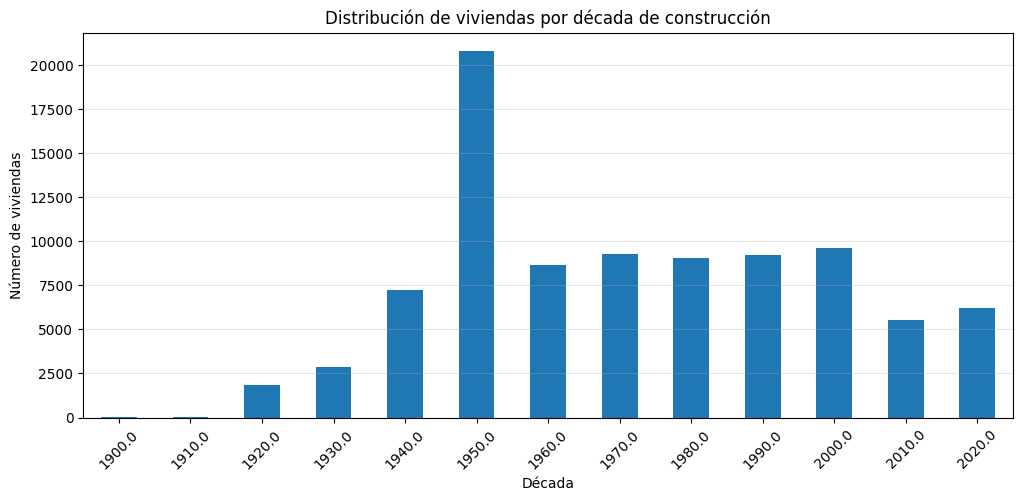

In [96]:

# Agrupamos los años de construcción por décadas

df_limpio_final['decada_construccion'] = (
    (df_limpio_final['year_built'] // 10) * 10
)

distribucion_decadas = (
    df_limpio_final['decada_construccion']
    .value_counts()
    .sort_index()
)

print("Número de viviendas por década:")
display(distribucion_decadas)

# Representamos la distribución
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

distribucion_decadas.plot(kind='bar')

plt.title('Distribución de viviendas por década de construcción')
plt.xlabel('Década')
plt.ylabel('Número de viviendas')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.show()


### 1.3.14 Análisis de list_price

In [97]:
# Comprobamos el tipo de dato
print("Tipo de dato:", df_limpio_final['list_price'].dtype)

# Convertimos temporalmente a formato numérico para analizarlo
precios = pd.to_numeric(
    df_limpio_final['list_price'],
    errors='coerce'
)

# Estadísticas descriptivas
print("\nEstadísticas de list_price:")
display(precios.describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
))

# Comprobamos valores nulos, ceros y negativos
print("\nValores nulos:", precios.isnull().sum())
print("Valores iguales a 0:", (precios == 0).sum())
print("Valores negativos:", (precios < 0).sum())

# Valores que no se han podido convertir a números
print(
    "Valores no numéricos:",
    (df_limpio_final['list_price'].notnull() & precios.isnull()).sum()
)

Tipo de dato: float64

Estadísticas de list_price:


count    9.182800e+04
mean     1.126507e+06
std      2.752312e+06
min      0.000000e+00
1%       3.500000e+03
5%       2.520700e+05
25%      4.700000e+05
50%      6.132000e+05
75%      8.962250e+05
90%      1.850000e+06
95%      3.221780e+06
99%      1.000000e+07
max      1.700000e+08
Name: list_price, dtype: float64


Valores nulos: 16
Valores iguales a 0: 72
Valores negativos: 0
Valores no numéricos: 0


Investigamos los precios iguales a 0

In [98]:
# Mostramos las viviendas cuyo precio de publicación es 0

columnas = [
    'street',
    'city',
    'beds',
    'baths',
    'sqft',
    'lot_sqft',
    'year_built',
    'list_price',
    'last_sold_price',
    'last_sold_date_clean'
]

display(
    df_limpio_final.loc[
        df_limpio_final['list_price'] == 0,
        columnas
    ]
)

,street,city,beds,baths,sqft,lot_sqft,year_built,list_price,last_sold_price,last_sold_date_clean
14270,1369 NW 69th St,Miami,3.0,1.0,1144.0,5227.0,1946.0,0.0,200000.0,2021-04-05
31340,8859 SW 223rd Ter,Cutler Bay,NaN,NaN,NaN,NaN,NaN,0.0,400100.0,2026-03-04
51763,14697 S Biscayne River Dr,Miami,4.0,2.0,2899.0,13939.0,1949.0,0.0,388000.0,2020-11-12
186203,4130 Collins Ave #304,Miami Beach,NaN,1.0,248.0,NaN,1936.0,0.0,160000.0,2020-05-20
223069,1801 NW 83rd Ter,Miami,2.0,1.0,978.0,6534.0,1955.0,0.0,370000.0,2022-01-11
...,...,...,...,...,...,...,...,...,...,...
922769,10850 NW 21st St STE 170,Miami,NaN,NaN,NaN,NaN,NaN,0.0,800000.0,2020-12-30
935254,15381 SW 112th Ter,Miami,5.0,3.0,3587.0,8712.0,1999.0,0.0,700000.0,2021-12-03
942008,9001 SW 197th St,Cutler Bay,5.0,3.0,2858.0,8800.0,1959.0,0.0,655000.0,2024-03-25
988848,1150 101st St #201,Miami Beach,2.0,2.0,998.0,NaN,2019.0,0.0,750000.0,2023-10-05


Se han identificado **72 registros con un precio de publicación (`list_price`) igual a cero**.

Al revisar estos registros, se observa que algunos tienen información de un precio de venta anterior (`last_sold_price`) con valores positivos. Esto indica que el valor cero de `list_price` no implica necesariamente que la vivienda se haya vendido sin coste, sino que podría tratarse de información no disponible o no registrada correctamente.

Por tanto, no se eliminarán estos registros automáticamente. Antes de decidir su tratamiento, se comprobará cuántos disponen de un precio de venta anterior y se valorará si resulta adecuado sustituir los ceros por valores nulos (`NaN`).

In [99]:
# Analizamos la información disponible en los registros con list_price = 0

registros_cero = df_limpio_final[
    df_limpio_final['list_price'] == 0
].copy()

print("Total de registros:", len(registros_cero))

print("\nValores nulos en otras variables:")
display(
    registros_cero.isnull().sum().sort_values(ascending=False)
)

print("\nInformación sobre el precio de última venta:")
print(
    "Con last_sold_price disponible:",
    registros_cero['last_sold_price'].notnull().sum()
)

print(
    "Con fecha de última venta disponible:",
    registros_cero['last_sold_date_clean'].notnull().sum()
)

print(
    "Con dormitorios disponibles:",
    registros_cero['beds'].notnull().sum()
)

print(
    "Con superficie disponible:",
    registros_cero['sqft'].notnull().sum()
)

Total de registros: 72

Valores nulos en otras variables:


hoa_fee                 55
parcel_apn              38
heating_type            34
lot_sqft                26
beds                    21
sqft                    19
baths                   19
year_built              16
decada_construccion     16
basement                 0
county_fips              0
source_count             0
last_sold_date_clean     0
hoa_fee_available        0
fireplace                0
waterfront               0
garage                   0
pool                     0
id                       0
central_air              0
last_sold_date           0
street                   0
list_price               0
status                   0
property_type            0
lng                      0
lat                      0
zip                      0
state                    0
city                     0
last_sold_price          0
dtype: int64


Información sobre el precio de última venta:
Con last_sold_price disponible: 72
Con fecha de última venta disponible: 72
Con dormitorios disponibles: 51
Con superficie disponible: 53


**Análisis de los registros con `list_price` igual a cero**

Se han revisado los 72 registros cuyo precio de publicación (`list_price`) es igual a cero.

Se ha comprobado que los 72 registros disponen de un último precio de venta (`last_sold_price`) y de su correspondiente fecha de venta. Además, 51 cuentan con información sobre dormitorios y 53 sobre superficie construida.

Por tanto, se considera que estos registros contienen información útil para el proyecto. Se decide conservar las viviendas y sustituir los valores cero de `list_price` por valores nulos (`NaN`), ya que no representan un precio de publicación válido.

Esta decisión permite conservar información relevante sobre las operaciones inmobiliarias sin introducir precios de publicación incorrectos.

In [100]:
# Sustituimos los precios de publicación iguales a 0 por valores nulos
df_limpio_final.loc[
    df_limpio_final['list_price'] == 0,
    'list_price'
] = np.nan

# Comprobamos el resultado
print("Valores nulos en list_price:", df_limpio_final['list_price'].isnull().sum())
print("Valores iguales a 0:", (df_limpio_final['list_price'] == 0).sum())
print("Valores negativos:", (df_limpio_final['list_price'] < 0).sum())

Valores nulos en list_price: 88
Valores iguales a 0: 0
Valores negativos: 0


Tras aplicar el tratamiento, los 72 valores de `list_price` iguales a cero se han sustituido por valores nulos (`NaN`). De este modo, la variable pasa a tener 88 valores nulos en total, sin eliminar los registros correspondientes. Se comprueba que no quedan valores iguales a cero ni negativos.

Revisamos los precios de publicación mas elevados

In [101]:
# Revisamos las 20 viviendas con mayor precio de publicación

display(
    df_limpio_final.nlargest(20, 'list_price')[
        [
            'street',
            'city',
            'beds',
            'baths',
            'sqft',
            'list_price',
            'last_sold_price'
        ]
    ]
)

,street,city,beds,baths,sqft,list_price,last_sold_price
983991,7 Indian Creek Island Rd,Indian Creek,9.0,13.0,27889.0,170000000.0,170000000.0
977143,18 La Gorce Cir,Miami Beach,12.0,20.5,NaN,122125121.0,122125121.0
968089,1420 W 23rd St,Miami Beach,9.0,10.0,10791.0,110000000.0,18500000.0
752642,3031 Brickell Ave,Miami,12.0,17.0,19919.0,106875000.0,106875000.0
907944,3585 Anchorage Way,Miami,13.0,16.5,11855.0,101500000.0,101500000.0
968224,3100 N Bay Rd,Miami Beach,7.0,9.0,10250.0,100000000.0,13600000.0
362343,702 SW 1st St,Miami,NaN,NaN,3966.0,92000000.0,92000000.0
398244,28 Indian Creek Island Rd,Indian Creek,6.0,9.0,12135.0,87000000.0,87000000.0
311436,4445 Sabal Palm Rd,Miami,12.0,12.0,20567.0,85200000.0,85200000.0
968039,1649 W 22nd St,Miami Beach,8.0,11.5,10385.0,85000000.0,19000000.0


**Análisis de los precios de publicación más elevados**

Se han revisado los 20 registros con mayor precio de publicación (list_price).

Se observa que una parte importante corresponde a viviendas de lujo, ubicadas en zonas como Indian Creek, Miami Beach y Coral Gables, y que presentan superficies construidas y características acordes con propiedades de alto valor.

Por tanto, no se considera adecuado eliminar estos registros únicamente por presentar precios elevados.

### 1.3.15 Análisis de last_sold_price

In [102]:
# Estadísticas descriptivas de last_sold_price

print("Tipo de dato:", df_limpio_final['last_sold_price'].dtype)

display(
    df_limpio_final['last_sold_price'].describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

# Comprobamos valores nulos, ceros y negativos

print("\nValores nulos:", df_limpio_final['last_sold_price'].isnull().sum())

print(
    "Valores iguales a 0:",
    (df_limpio_final['last_sold_price'] == 0).sum()
)

print(
    "Valores negativos:",
    (df_limpio_final['last_sold_price'] < 0).sum()
)

Tipo de dato: float64


count    9.184300e+04
mean     9.758270e+05
std      2.415769e+06
min      0.000000e+00
1%       8.706800e+04
5%       2.500000e+05
25%      4.020000e+05
50%      5.470000e+05
75%      7.950000e+05
90%      1.567900e+06
95%      2.700000e+06
99%      8.600000e+06
max      1.700000e+08
Name: last_sold_price, dtype: float64


Valores nulos: 1
Valores iguales a 0: 1
Valores negativos: 0


Vamos a investigar el registro donde el precio de venta = 0

In [103]:
# Identificamos el registro con last_sold_price = 0

columnas = [
    'street',
    'city',
    'beds',
    'baths',
    'sqft',
    'lot_sqft',
    'year_built',
    'list_price',
    'last_sold_price',
    'last_sold_date_clean'
]

display(
    df_limpio_final.loc[
        df_limpio_final['last_sold_price'] == 0,
        columnas
    ]
)

,street,city,beds,baths,sqft,lot_sqft,year_built,list_price,last_sold_price,last_sold_date_clean
912805,7135 NW 36th Ave,Miami,NaN,NaN,NaN,NaN,NaN,669200.0,0.0,2020-10-26


Tras contrastar la información disponible sobre esta vivienda, no ha sido posible verificar el importe real de la última transacción. Por este motivo, se sustituye el valor de last_sold_price por un valor nulo (NaN), conservando el resto del registro.

In [104]:
# Sustituimos el precio de venta igual a 0 por NaN

df_limpio_final.loc[
    df_limpio_final['last_sold_price'] == 0,
    'last_sold_price'
] = np.nan

# Comprobamos el resultado

print(
    "Valores nulos:",
    df_limpio_final['last_sold_price'].isnull().sum()
)

print(
    "Valores iguales a 0:",
    (df_limpio_final['last_sold_price'] == 0).sum()
)

Valores nulos: 2
Valores iguales a 0: 0


Ahora investiguemos el otro valor nulo

In [105]:
# Localizamos el registro con last_sold_price nulo

registro_nulo = df_limpio_final[
    df_limpio_final['last_sold_price'].isnull()
]

columnas = [
    'street',
    'city',
    'beds',
    'baths',
    'sqft',
    'lot_sqft',
    'year_built',
    'list_price',
    'last_sold_price',
    'last_sold_date_clean'
]

display(registro_nulo[columnas])

,street,city,beds,baths,sqft,lot_sqft,year_built,list_price,last_sold_price,last_sold_date_clean
904934,11400 NW 34th St,Doral,NaN,NaN,NaN,NaN,NaN,1018400.0,NaN,2020-02-13
912805,7135 NW 36th Ave,Miami,NaN,NaN,NaN,NaN,NaN,669200.0,NaN,2020-10-26


Se ha identificado otro registro sin información sobre el importe de la última venta. Al no disponer de un precio verificable, se conserva el inmueble, manteniendo last_sold_price como valor nulo (NaN).

Estudiemos ahora los valores extremos

In [106]:
# Calculamos el percentil 99
p99 = df_limpio_final['last_sold_price'].quantile(0.99)

print(f"Percentil 99: {p99:,.2f} $")

# Seleccionamos las viviendas por encima del percentil 99
precios_extremos = df_limpio_final[
    df_limpio_final['last_sold_price'] > p99
].copy()

print("Número de registros extremos:", len(precios_extremos))
print(
    "Porcentaje sobre el dataset:",
    round(len(precios_extremos) / len(df_limpio_final) * 100, 2),
    "%"
)

# Mostramos los 30 precios más elevados
columnas = [
    'street',
    'city',
    'beds',
    'baths',
    'sqft',
    'lot_sqft',
    'year_built',
    'last_sold_price',
    'last_sold_date_clean'
]

display(
    precios_extremos.nlargest(
        30, 'last_sold_price'
    )[columnas]
)

Percentil 99: 8,600,000.00 $
Número de registros extremos: 916
Porcentaje sobre el dataset: 1.0 %


,street,city,beds,baths,sqft,lot_sqft,year_built,last_sold_price,last_sold_date_clean
983991,7 Indian Creek Island Rd,Indian Creek,9.0,13.0,27889.0,80000.0,2026.0,170000000.0,2026-03-02
977143,18 La Gorce Cir,Miami Beach,12.0,20.5,NaN,125161.0,1936.0,122125121.0,2024-10-25
1008388,10380 NW 68th Ter,Doral,5.0,5.0,3000.0,3730.0,2020.0,107800000.0,2024-09-12
752642,3031 Brickell Ave,Miami,12.0,17.0,19919.0,182400.0,1913.0,106875000.0,2022-09-02
1014775,6470 SW 33rd St,Miami,4.0,3.0,NaN,NaN,2018.0,102700000.0,2025-09-11
907944,3585 Anchorage Way,Miami,13.0,16.5,11855.0,178150.0,2008.0,101500000.0,2025-12-29
362343,702 SW 1st St,Miami,NaN,NaN,3966.0,63366.0,2021.0,92000000.0,2022-07-01
398244,28 Indian Creek Island Rd,Indian Creek,6.0,9.0,12135.0,79997.0,2002.0,87000000.0,2024-06-03
311436,4445 Sabal Palm Rd,Miami,12.0,12.0,20567.0,73089.0,2008.0,85200000.0,2025-01-10
983987,12 Indian Creek Island Rd,Indian Creek,7.0,12.5,19064.0,80000.0,2000.0,79000000.0,2023-10-12


Que esl precio sea tan elevado o quiere decir que este mal, sino que son casas de lujo y estan en zonas muy buenas.

Lo que vamos a hacer a continuación es crear una varible que es precio por sqft

In [107]:
# Calculamos el precio de venta por pie cuadrado

precios_extremos['precio_sqft'] = (
    precios_extremos['last_sold_price'] /
    precios_extremos['sqft']
)

# Ordenamos de mayor a menor precio por sqft

display(
    precios_extremos[
        [
            'street',
            'city',
            'beds',
            'baths',
            'sqft',
            'last_sold_price',
            'precio_sqft'
        ]
    ].sort_values(
        'precio_sqft',
        ascending=False
    ).head(30)
)

,street,city,beds,baths,sqft,last_sold_price,precio_sqft
344572,3301 Devon Rd,Miami,NaN,NaN,253.0,20000000.0,79051.383399
411542,9501 SW 137th Ave,Miami,NaN,NaN,200.0,14364000.0,71820.000000
783520,3025 SW 13th St,Miami,3.0,2.0,1176.0,74500000.0,63350.340136
1008388,10380 NW 68th Ter,Doral,5.0,5.0,3000.0,107800000.0,35933.333333
304245,6060 Indian Creek Dr,Miami Beach,NaN,NaN,379.0,11000000.0,29023.746702
362343,702 SW 1st St,Miami,NaN,NaN,3966.0,92000000.0,23197.175996
57138,6596 Allison Rd,Miami Beach,NaN,NaN,2265.0,51000000.0,22516.556291
290225,1550 NE Miami Pl,Miami,3.0,1.0,1049.0,19750000.0,18827.454719
436201,11420 SW 248th Ter,Homestead,2.0,2.0,1391.0,22520800.0,16190.366643
114248,275 NE 18th St SUITE CU1,Miami,NaN,NaN,1255.0,15450000.0,12310.756972


El precio por sqft permite contextualizar los precios de venta más elevados e identificar posibles inconsistencias. Los registros con valores especialmente altos se revisarán individualmente antes de decidir si es necesario modificar algún dato.

In [108]:
# Corregimos el precio de venta de 3025 SW 13th St

condicion = (
    df_limpio_final['street'].str.contains(
        '3025 SW 13th St',
        case=False,
        na=False
    )
)

df_limpio_final.loc[
    condicion,
    'last_sold_price'
] = 750000

# Comprobamos la corrección
display(
    df_limpio_final.loc[
        condicion,
        ['street', 'city', 'last_sold_price']
    ]
)

,street,city,last_sold_price
783520,3025 SW 13th St,Miami,750000.0


## 1.4 Analicemos las variables categóricas

Empezamos por city

In [109]:
# Número de ciudades diferentes
print("Número de ciudades:", df_limpio_final['city'].nunique())

# Frecuencia de las 30 ciudades más representadas
display(
    df_limpio_final['city']
    .value_counts(dropna=False)
    .head(30)
)

Número de ciudades: 60


city
Miami                 44120
Homestead             10573
Hialeah                6565
Miami Gardens          4940
Coral Gables           2994
Cutler Bay             2787
Doral                  2351
Miami Beach            2140
Palmetto Bay           1958
North Miami            1745
North Miami Beach      1657
Pinecrest              1468
Miami Lakes            1137
Miami Shores           1017
Opa Locka               911
Florida City            848
South Miami             717
Miami Springs           705
Key Biscayne            457
Hialeah Gardens         408
Surfside                362
Aventura                324
Biscayne Park           282
West Miami              247
El Portal               207
Sweetwater              174
Golden Beach            151
North Bay Village       150
Sunny Isles Beach       133
Bay Harbor Islands      100
Name: count, dtype: int64

A primera vista, la distribución city parece coherente. Tenemos una concentración importante en Miami, seguida de Homestad, Hialeah y Miami Gardens.

Tambien encontramos otras localidades de Miami como Coral Gables, Doral, Miami Beach...

Ahora comprobaremos nombres inconsistentes es decir si existen ciudades duplicadas por diferencia de escritura, espacios o mayúsculas. Por ejemplo Miami, MIAMI deberían representar la misma categoría.

In [110]:
# Comprobamos posibles diferencias de escritura en city

ciudades_originales = df_limpio_final['city'].dropna().unique()

ciudades_normalizadas = (
    df_limpio_final['city']
    .dropna()
    .str.strip()
    .str.lower()
    .unique()
)

print("Ciudades diferentes originales:", len(ciudades_originales))
print("Ciudades diferentes normalizadas:", len(ciudades_normalizadas))

Ciudades diferentes originales: 60
Ciudades diferentes normalizadas: 60


Ya tenemos esta variable normalizada.

In [111]:
# Identificamos los nombres originales que cambian al normalizarlos

comparacion_ciudades = pd.DataFrame({
    'ciudad_original': df_limpio_final['city'].dropna().unique()
})

comparacion_ciudades['ciudad_normalizada'] = (
    comparacion_ciudades['ciudad_original']
    .str.strip()
    .str.lower()
)

display(
    comparacion_ciudades[
        comparacion_ciudades['ciudad_original'] !=
        comparacion_ciudades['ciudad_normalizada']
    ].sort_values('ciudad_normalizada')
)

,ciudad_original,ciudad_normalizada
9,Aventura,aventura
24,Bal Harbour,bal harbour
25,Bay Harbor Islands,bay harbor islands
30,Biscayne Park,biscayne park
54,Bonita Springs,bonita springs
32,Coconut Grove,coconut grove
11,Coral Gables,coral gables
41,Corral Gables,corral gables
6,Cutler Bay,cutler bay
4,Doral,doral


In [112]:
# Normalizamos los nombres de las ciudades
df_limpio_final['city'] = (
    df_limpio_final['city']
    .str.strip()
    .str.lower()
    .str.title()
)

# Comprobamos el resultado
print("Ciudades diferentes:", df_limpio_final['city'].nunique())

display(
    df_limpio_final['city']
    .value_counts()
    .head(20)
)

Ciudades diferentes: 60


city
Miami                44120
Homestead            10573
Hialeah               6565
Miami Gardens         4940
Coral Gables          2994
Cutler Bay            2787
Doral                 2351
Miami Beach           2140
Palmetto Bay          1958
North Miami           1745
North Miami Beach     1657
Pinecrest             1468
Miami Lakes           1137
Miami Shores          1017
Opa Locka              911
Florida City           848
South Miami            717
Miami Springs          705
Key Biscayne           457
Hialeah Gardens        408
Name: count, dtype: int64

La siguiente variable a estudiar es **zip**, vamos a comprobar la distribución de los códigos postales. ya que la ubicación mas precisa puede ser importante para nuestro proyecto.

Buscamos detectar posibles problemas de formato o valores extraños, sin modificar nada.

In [113]:
# Revisamos los códigos postales

print("Número de códigos postales diferentes:",
      df_limpio_final['zip'].nunique())

print("Valores nulos:",
      df_limpio_final['zip'].isnull().sum())

display(
    df_limpio_final['zip']
    .value_counts(dropna=False)
    .head(30)
)

Número de códigos postales diferentes: 81
Valores nulos: 9


zip
33033.0    3962
33157.0    3958
33032.0    3149
33177.0    2988
33186.0    2490
33165.0    2321
33155.0    2281
33156.0    2266
33176.0    2227
33196.0    2060
33147.0    2035
33134.0    2018
33018.0    1998
33175.0    1922
33178.0    1861
33030.0    1845
33143.0    1736
33133.0    1623
33138.0    1622
33162.0    1620
33056.0    1593
33055.0    1577
33142.0    1569
33161.0    1548
33015.0    1430
33169.0    1401
33054.0    1384
33189.0    1370
33012.0    1367
33185.0    1298
Name: count, dtype: int64

In [114]:
print("Tipo de dato:", df_limpio_final['zip'].dtype)

print("Valores nulos:", df_limpio_final['zip'].isnull().sum())

print("Códigos postales diferentes:", df_limpio_final['zip'].nunique())

print("Valor mínimo:", df_limpio_final['zip'].min())

print("Valor máximo:", df_limpio_final['zip'].max())

Tipo de dato: float64
Valores nulos: 9
Códigos postales diferentes: 81
Valor mínimo: 33010.0
Valor máximo: 37330.0


Vamos a guardar estos valores como texto, ya que están como float, pero los códigos postales no son magnitudes numñericas, sino que son identificadores. Por lo que los guardaremos como texto, para evitar problemas de formato.

In [115]:
# Convertimos los códigos postales a texto,
# conservando los valores nulos

df_limpio_final['zip'] = (
    df_limpio_final['zip']
    .astype('Int64')
    .astype('string')
)

# Comprobamos el resultado

print("Nuevo tipo de dato:", df_limpio_final['zip'].dtype)
print("Valores nulos:", df_limpio_final['zip'].isnull().sum())

display(df_limpio_final['zip'].value_counts().head(10))

Nuevo tipo de dato: string
Valores nulos: 9


zip
33033    3962
33157    3958
33032    3149
33177    2988
33186    2490
33165    2321
33155    2281
33156    2266
33176    2227
33196    2060
Name: count, dtype: int64[pyarrow]

Ahora pasamos a la variable state, donde coprobaremos si todos los registros pertenecen al mismo estado.

In [116]:
# Comprobamos la distribución de los estados

print("Estados diferentes:", df_limpio_final['state'].nunique())

print("\nFrecuencia por estado:")

display(
    df_limpio_final['state']
    .value_counts(dropna=False)
)

Estados diferentes: 3

Frecuencia por estado:


state
FL    91840
AL        3
TN        1
Name: count, dtype: int64

Tenemos una pequeña incostistencia, nuestro proyecto se centra exclusivamente en Miami-Dade Country, Florida, y observamos que hay 4 regsitros que no coincide con este estado.

Vamos a investigar estos 4 registros

In [117]:
# Identificamos los registros que no pertenecen a Florida

registros_otros_estados = df_limpio_final[
    df_limpio_final['state'] != 'FL'
]

display(
    registros_otros_estados[
        ['street', 'city', 'state', 'zip', 'last_sold_price']
    ]
)

,street,city,state,zip,last_sold_price
702018,1382 Bonner Way,Estill Springs,TN,37330,200000.0
939443,812 Clearmont Dr,Dothan,AL,33177,43393.0
939444,1113 Valley Forge Rd,Dothan,AL,33177,92000.0
939445,1309 Choctaw St,Dothan,AL,33177,113500.0


Como son registros que no pertnecen al estado de Florida, vamos a eliminarlos.

In [118]:
# Eliminamos los registros que no pertenecen a Florida

filas_antes = len(df_limpio_final)

df_limpio_final = df_limpio_final[
    df_limpio_final['state'] == 'FL'
].copy()

filas_despues = len(df_limpio_final)

print("Filas antes:", filas_antes)
print("Filas después:", filas_despues)
print("Registros eliminados:", filas_antes - filas_despues)

Filas antes: 91844
Filas después: 91840
Registros eliminados: 4


Ahora pasemos a analizar la variable **street**, para ver si hay calles duplicadas o problemas de formato. Primero veremos cuántas direcciones diferentes tenemos y si hay valores nulos.

In [119]:
print("Tipo de dato:", df_limpio_final['street'].dtype)
print("Valores nulos:", df_limpio_final['street'].isnull().sum())
print("Direcciones diferentes:", df_limpio_final['street'].nunique())
print("Direcciones duplicadas:", df_limpio_final['street'].duplicated().sum())

Tipo de dato: str
Valores nulos: 0
Direcciones diferentes: 91430
Direcciones duplicadas: 410


Ahora vamos a comprobar el formato de las direcciones.

In [120]:
# Comprobamos posibles diferencias de formato

direcciones_originales = df_limpio_final['street'].nunique()

direcciones_normalizadas = (
    df_limpio_final['street']
    .str.strip()
    .str.lower()
    .nunique()
)

print("Direcciones originales:", direcciones_originales)
print("Direcciones normalizadas:", direcciones_normalizadas)

Direcciones originales: 91430
Direcciones normalizadas: 91415


Aquí sí hemos detectado una pequeña diferencia:
- Direcciones originales: 91.430
- Direcciones normalizadas: 91.415
- Diferencia: 15 direcciones
Esto significa que hay algunas direcciones que aparecen escritas de formas ligeramente diferentes, por ejemplo, por espacios adicionales o diferencias entre mayúsculas y minúsculas.

Identificamos ahora las direcciones afectadas


In [121]:
# Creamos una versión normalizada de las direcciones
direcciones = df_limpio_final['street'].str.strip().str.lower()

# Buscamos direcciones que tienen distintas escrituras
# pero coinciden después de normalizarlas

revision_direcciones = pd.DataFrame({
    'direccion_original': df_limpio_final['street'],
    'direccion_normalizada': direcciones
})

diferencias = (
    revision_direcciones
    .groupby('direccion_normalizada')['direccion_original']
    .nunique()
)

direcciones_a_revisar = diferencias[diferencias > 1].index

display(
    revision_direcciones[
        revision_direcciones['direccion_normalizada'].isin(
            direcciones_a_revisar
        )
    ].drop_duplicates().sort_values('direccion_normalizada')
)

,direccion_original,direccion_normalizada
675119,1184 Nw 3rd St,1184 nw 3rd st
746233,1184 NW 3rd St,1184 nw 3rd st
264958,11983 SW 269th Ter,11983 sw 269th ter
704646,11983 Sw 269th Ter,11983 sw 269th ter
241959,13210 SW 257th Ter,13210 sw 257th ter
751655,13210 Sw 257th Ter,13210 sw 257th ter
705220,14440 Sw 19th St,14440 sw 19th st
710671,14440 SW 19th St,14440 sw 19th st
421937,15174 SW 114th St,15174 sw 114th st
743479,15174 Sw 114th St,15174 sw 114th st


Las principales diferencias se deben exclusivamente a mayúsculas y minúsculas.

Para la limpieza tomaremos las siguientes decisiones:


*   Eliminar espacios al principio y al final.
*   No eliminar direcciones repetidas.


*   Convertir todas las direcciones a mayúsculas.

*   Conservar todos los registros.







In [122]:
# Normalizamos el formato de las direcciones

df_limpio_final['street'] = (
    df_limpio_final['street']
    .str.strip()
    .str.upper()
)

# Comprobamos el resultado

print(
    "Direcciones diferentes después de normalizar:",
    df_limpio_final['street'].nunique()
)

print(
    "Direcciones duplicadas:",
    df_limpio_final['street'].duplicated().sum()
)

display(df_limpio_final['street'].head(10))

Direcciones diferentes después de normalizar: 91415
Direcciones duplicadas: 425


12    4260 NW 168TH TER
30     4421 NW 171ST ST
34     4450 NW 170TH ST
36     4480 NW 170TH ST
42    4427 NW 169TH TER
47     3850 NW 179TH ST
75     3871 NW 178TH ST
81     3990 NW 179TH ST
89     3911 NW 178TH ST
94     3971 NW 178TH ST
Name: street, dtype: str

Ahora pasamos a estudiar laa variable **status**.

Para ello vamos a comprobar los estados de publicación de las viviendas para identificar categorías importantes.


In [123]:
print("Valores nulos:", df_limpio_final['status'].isnull().sum())

print("Categorías diferentes:", df_limpio_final['status'].nunique())

display(
    df_limpio_final['status']
    .value_counts(dropna=False)
)

Valores nulos: 0
Categorías diferentes: 6


status
off_market     71922
sold           14509
active          3139
other           2191
pending           53
coming_soon       26
Name: count, dtype: int64

No tocamos nada de esta variable.

Ahora pasemos a estudiar la variable **property_type**.

Aunque ya filtramos por viviendas unifamiliares, quiero comprobar que todos los registros conservados pertenecen realmente a single_family.

In [124]:
print("Tipos de propiedad diferentes:",
      df_limpio_final['property_type'].nunique())

display(
    df_limpio_final['property_type']
    .value_counts(dropna=False)
)

Tipos de propiedad diferentes: 1


property_type
single_family    91840
Name: count, dtype: int64

La siguiente variable a estudiar es **county_fips**.

Esta variable identifica el condado mediante un código FIPS. Como trabajmos solo con Miami, queremos comprobar que todos los registros corresponden al mismo condado.

In [125]:
print("Códigos FIPS diferentes:",
      df_limpio_final['county_fips'].nunique())

print("Valores nulos:",
      df_limpio_final['county_fips'].isnull().sum())

display(
    df_limpio_final['county_fips']
    .value_counts(dropna=False)
)

Códigos FIPS diferentes: 1
Valores nulos: 0


county_fips
12086    91840
Name: count, dtype: int64

Ahora estudiemos el **id**.

Para ver si hay valores nulos o repetidos.

In [126]:
print("Valores nulos:", df_limpio_final['id'].isnull().sum())

print("Identificadores diferentes:", df_limpio_final['id'].nunique())

print("Identificadores duplicados:", df_limpio_final['id'].duplicated().sum())

Valores nulos: 0
Identificadores diferentes: 91840
Identificadores duplicados: 0


Siguiente variable **source_count**.

Esta variable nos indica el número de fuents de información asociadas a cada registro. Vamos a comprobar su distribución para detectar varlores anómalos.

In [127]:
print("Valores nulos:", df_limpio_final['source_count'].isnull().sum())

print("Valores diferentes:", df_limpio_final['source_count'].nunique())

display(
    df_limpio_final['source_count']
    .value_counts(dropna=False)
    .sort_index()
)

Valores nulos: 0
Valores diferentes: 35


source_count
1      36799
2      54806
3        160
4         12
5          7
6          2
7          3
8          7
9          3
10         4
11         4
12         1
13         5
14         2
15         2
16         2
19         1
23         2
24         2
25         1
26         1
30         1
31         1
32         1
35         1
37         1
42         1
44         1
45         1
60         1
61         1
62         1
71         1
72         1
178        1
Name: count, dtype: int64

Interpretación de los resultados
- Valores diferentes: 35.
- La mayoría de los registros tienen 1 o 2 fuentes.
- 36.799 viviendas tienen una fuente.
- 54.806 viviendas tienen dos fuentes.
- A partir de 3 fuentes, la frecuencia disminuye considerablemente.
- Encontramos un valor máximo de 178 fuentes, que merece una comprobación.

Investiguemos el máximo, es decir la vivienda que tiene 178 fuentes.



In [128]:
# Identificamos los registros con el máximo source_count

max_source = df_limpio_final['source_count'].max()

print("Máximo source_count:", max_source)

display(
    df_limpio_final.loc[
        df_limpio_final['source_count'] == max_source,
        ['street', 'city', 'zip', 'source_count',
         'beds', 'baths', 'sqft', 'last_sold_price']
    ]
)

Máximo source_count: 178


,street,city,zip,source_count,beds,baths,sqft,last_sold_price
957534,100 S POINTE DR APT 910,Miami Beach,33139,178,3.0,3.0,NaN,2980000.0


Contrastando la información esta vivienda tiene 2.122 sqft, por lo que actualizamos los datos.

He sacado la información de aqui https://www.southfloridainvestments.com/info/property/residential/A12071573/

In [129]:
# Corregimos la superficie de la vivienda

condicion = (
    df_limpio_final['street'].str.contains(
        '100 S POINTE DR APT 910',
        case=False,
        na=False
    )
)

df_limpio_final.loc[condicion, 'sqft'] = 2122

# Comprobamos el resultado

display(
    df_limpio_final.loc[
        condicion,
        ['street', 'beds', 'baths', 'sqft',
         'last_sold_price', 'source_count']
    ]
)

,street,beds,baths,sqft,last_sold_price,source_count
957534,100 S POINTE DR APT 910,3.0,3.0,2122.0,2980000.0,178


La siguiente variable a revisar es **heating_type**.

Corresponde a los distintos tio de calefacción, donde comprobaremos sus categorías, valores nulos y posibles incosistencias.

In [130]:
print("Valores nulos:",
      df_limpio_final['heating_type'].isnull().sum())

print("Categorías diferentes:",
      df_limpio_final['heating_type'].nunique())

display(
    df_limpio_final['heating_type']
    .value_counts(dropna=False)
)

Valores nulos: 18852
Categorías diferentes: 9


heating_type
other         33148
electric      19997
NaN           18852
forced_air    16781
none           1375
wall            893
heat_pump       378
gas             361
baseboard        49
radiant           6
Name: count, dtype: int64

Los valores nulos los dejaria como nulos ya que los NaN es que desconocemos qué sistema de calefacción tiene y el none sabemos a ciencia cierta que la vivienda no tiene calefacción. Por lo que no debemos confucndir ambas situaciones. Asique si sustituimos los nulos por none, estaríamos afirmando que esas viviendas no tienen calefacción sin tener pruebas.

### 1.5 Validación global del dataset

Ahora nos toca comprobar que todas las decisiones de limpieza se ham aplicado correctamente y que no hemos introducido inconsistencias.

Empezaremos comprobando las dimensiones, los valores nulos y los duplicados.

In [131]:
# Dimensiones finales
print("Número de filas:", df_limpio_final.shape[0])
print("Número de columnas:", df_limpio_final.shape[1])

# Valores nulos por variable
nulos_finales = pd.DataFrame({
    'Valores nulos': df_limpio_final.isnull().sum(),
    'Porcentaje nulos': df_limpio_final.isnull().mean() * 100
})

display(
    nulos_finales.sort_values(
        'Porcentaje nulos',
        ascending=False
    )
)

# Duplicados exactos
print(
    "Duplicados exactos:",
    df_limpio_final.duplicated().sum()
)

Número de filas: 91840
Número de columnas: 31


,Valores nulos,Porcentaje nulos
hoa_fee,71858,78.242596
heating_type,18852,20.527003
lot_sqft,5266,5.733885
sqft,1952,2.125436
decada_construccion,1600,1.742160
year_built,1600,1.742160
parcel_apn,1404,1.528746
beds,912,0.993031
baths,885,0.963632
list_price,88,0.095819


Duplicados exactos: 0


Vamos a comprobar los tipos de los datos

In [132]:
# Comprobamos los tipos de datos de todas las columnas

display(
    pd.DataFrame({
        'Variable': df_limpio_final.columns,
        'Tipo de dato': df_limpio_final.dtypes.astype(str).values
    })
)

,Variable,Tipo de dato
0,id,str
1,street,str
2,city,str
3,state,str
4,zip,string
5,lat,float64
6,lng,float64
7,property_type,str
8,beds,float64
9,baths,float64


La gran parte de las variables tienen un formato correcto, pero hay dos variables que las podemos mejorar, que son year_built y  decada_construccion que son ambos float y los queremos poner como enteros ya que son años.

In [133]:
# Convertimos los años a enteros que admiten valores nulos

df_limpio_final['year_built'] = (
    df_limpio_final['year_built'].astype('Int64')
)

df_limpio_final['decada_construccion'] = (
    df_limpio_final['decada_construccion'].astype('Int64')
)

# Comprobamos los cambios

print("year_built:", df_limpio_final['year_built'].dtype)
print("decada_construccion:", df_limpio_final['decada_construccion'].dtype)

year_built: Int64
decada_construccion: Int64


In [134]:
# Recalculamos la década a partir del año de construcción limpio
df_limpio_final['decada_construccion'] = (
    (df_limpio_final['year_built'] // 10) * 10
).astype('Int64')

# Comprobamos el resultado
display(
    df_limpio_final.loc[
        df_limpio_final['year_built'].isnull(),
        ['street', 'year_built', 'decada_construccion']
    ]
)

,street,year_built,decada_construccion
1984,3461 NW 177TH TERRACE,<NA>,<NA>
2740,471 E 63RD ST,<NA>,<NA>
2844,5150 E 9TH LN,<NA>,<NA>
6395,1531 NW 55TH TER,<NA>,<NA>
6713,1059 NW 48TH ST,<NA>,<NA>
...,...,...,...
961975,6460 SW 133RD DR,<NA>,<NA>
973580,5794 SW 151ST AVE,<NA>,<NA>
982313,11201 SW 108TH CT,<NA>,<NA>
1010057,6270 SW 102ND ST,<NA>,<NA>


Ahora el siguiente paso es comparar el dataset original con el dataset limpio.

In [135]:
# Comparación entre el dataset original y el dataset limpio

print("Dataset original:", len(df))
print("Dataset limpio:", len(df_limpio_final))

registros_eliminados = len(df) - len(df_limpio_final)

print("Registros eliminados:", registros_eliminados)

print(
    "Porcentaje conservado:",
    round(len(df_limpio_final) / len(df) * 100, 2),
    "%"
)

Dataset original: 1015955
Dataset limpio: 91840
Registros eliminados: 924115
Porcentaje conservado: 9.04 %


Aunque hayamos eliminado una gran cantidad de registros, hemos realizado dos limpiezas bastante considerables:

*   Selección del alcance: decidimos trabajar exclusivamente con viviendas unifamiliares (single_family) y ventas desde 2020.
*   Limpieza de datos: posteriormente eliminamos registros que no cumplían determinados criterios de calidad.



In [136]:
# Convertir el identificador catastral a texto
df_limpio_final["parcel_apn"] = df_limpio_final["parcel_apn"].astype("string")

# Comprobar el tipo de dato
print(df_limpio_final["parcel_apn"].dtype)

string


# Creamos el archivo silver

In [143]:
import os

# Ruta desde notebooks hasta data/processed
ruta_silver = "../data/processed"

os.makedirs(ruta_silver, exist_ok=True)

ruta_archivo = os.path.join(
    ruta_silver,
    "housingpulse_miami_silver.csv"
)

df_limpio_final.to_csv(
    ruta_archivo,
    index=False,
    encoding="utf-8"
)

print("Dataset Silver guardado correctamente.")
print("Ruta:", os.path.abspath(ruta_archivo))
print("Dimensiones:", df_limpio_final.shape)

Dataset Silver guardado correctamente.
Ruta: /Users/jorgete/Documents/master/ProyectoFinal-Evolve-2026/ProyectoFinalEvovle/Actividad_1_Evolve/data/processed/housingpulse_miami_silver.csv
Dimensiones: (91840, 31)


In [144]:
df_silver = pd.read_csv(ruta_archivo)

print("Comprobación del archivo Silver")
print("Dimensiones:", df_silver.shape)

display(df_silver.head())

Comprobación del archivo Silver
Dimensiones: (91840, 31)


,id,street,city,state,zip,lat,lng,property_type,beds,baths,...,garage,waterfront,fireplace,basement,parcel_apn,county_fips,source_count,last_sold_date_clean,hoa_fee_available,decada_construccion
0,stp_bj8GEByZzp,4260 NW 168TH TER,Miami Gardens,FL,33055.0,25.926702,-80.27009,single_family,4.0,2.0,...,True,False,False,False,3421080031080.0,12086,1,2020-11-24,False,1970.0
1,stp_GkoP4Z9b1y,4421 NW 171ST ST,Miami Gardens,FL,33055.0,25.929170,-80.27367,single_family,3.0,2.0,...,False,False,False,False,3421080060220.0,12086,1,2021-01-04,False,1970.0
2,stp_vzm0eZ2M1y,4450 NW 170TH ST,Miami Gardens,FL,33055.0,25.928220,-80.27386,single_family,3.0,2.0,...,False,False,False,False,3421080060260.0,12086,1,2020-01-08,False,1970.0
3,stp_KzKwbJLLzB,4480 NW 170TH ST,Miami Gardens,FL,33055.0,25.927982,-80.27467,single_family,3.0,1.0,...,True,False,False,False,3421080060290.0,12086,1,2020-03-13,False,1970.0
4,stp_l10lEveM1Z,4427 NW 169TH TER,Miami Gardens,FL,33055.0,25.927519,-80.27334,single_family,3.0,1.0,...,True,False,False,False,3421080060380.0,12086,1,2020-06-15,False,1970.0
